# Inventory Movement Review, FY2026 (Jul 2025 to Jun 2026)

This notebook answers four questions about how our stock moved over the year, in plain language for a management audience:

1. **Which products barely move, which are falling, and which are unpredictable?**
2. **When a number looks unusual, is it really unusual, and what caused it?**
3. **Is activity spread evenly, or do a few products do most of the work?**
4. **What else in the data looks wrong or worth fixing?**

Each question ends with a **key messages** cell that prints the findings as sentences with the current numbers, and every chart title states its finding. Charts are saved to `outputs/figures/`, result tables to `outputs/analysis_tables.xlsx`.

**How to run:** put the six CSV extracts in `data/` (file names as in `FILES` below), then *Kernel > Restart & Run All* (about 20 seconds).


## 1. Setup and configuration

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", "{:,.2f}".format)

# ---- paths: the folder holding the six CSV files ----
DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# The six CSV extracts (Jul 2025 to Jun 2026). Change a file name here if yours differs.
FILES = {
    "product_master": "product_master.csv",
    "items_unit_conversion": "items_unit_conversion.csv",
    "inventsite": "inventsite.csv",
    "inventlocation": "inventlocation.csv",
    "item_summary": "inventory_trans_item_summary.csv",
    "monthly": "inventtrans_monthly_summary.csv",
}

# Columns read as text (IDs and codes keep leading zeros and are never parsed as numbers)
TEXT_COLS = {
    "product_master": ["product_id", "product_name", "product_category", "category_level1", "category_level2",
                       "category_level3", "category_level4", "category_level5", "Product_lifecycle_state",
                       "UOM", "base_UOM", "inv_uom", "pur_uom", "sale_uom", "ship_group_id",
                       "material_group", "cost_group_id", "dataareaid"],
    "items_unit_conversion": ["item_id", "fromsymbol", "tosymbol"],
    "inventsite": ["siteid", "name", "dataareaid", "destinationcodeid_emp"],
    "inventlocation": ["inventlocationid", "inventsiteid", "name", "temperature_emp", "dataareaid"],
    "item_summary": ["item_id", "unit_of_measure"],
    "monthly": ["itemid", "site_id", "warehouse_id", "reference", "unitid"],
}
# ISO-8601 UTC timestamps in the extracts (e.g. 2025-07-01T00:00:00.000Z)
DATE_COLS = {
    "product_master": ["created_on", "modified_on"],
    "item_summary": ["first_transaction_date", "last_transaction_date"],
    "monthly": ["movement_month", "last_receipt_date", "last_issue_date", "last_movement_date"],
}

FY_START, FY_END = pd.Timestamp("2025-07-01"), pd.Timestamp("2026-06-01")
MONTHS = pd.date_range(FY_START, FY_END, freq="MS")
MONTH_LABELS = [m.strftime("%b %y") for m in MONTHS]

# ---- analysis thresholds (documented in the write-up; tune here) ----
SLOW_MAX_ACTIVE_MONTHS = 3            # demand in <= 3 of 12 months
SLOW_RECENCY_CUTOFF = pd.Timestamp("2026-04-01")   # no movement in the last quarter
DECLINE_SLOPE_PCT = -0.05             # robust slope < -5% of mean per month
DECLINE_HALF_RATIO = 0.70             # Jan-Jun demand < 70% of Jul-Dec
DECLINE_MIN_ACTIVE = 6
VOLATILE_CV = 1.0
VOLATILE_MIN_ACTIVE = 4               # fewer active months = slow mover, not volatile
VOLATILE_COST_INDEX = 80
ANOMALY_Z = 3.5                       # robust z threshold (Iglewicz-Hoaglin)
GLOBAL_PCT = 0.99                     # top 1% of the unit = "large vs the dataset"
Z_SCALE_FLOOR = 0.4                   # min spread on log1p scale (~1.5x); stops flat series giving huge z

# ---- chart style ----
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "figure.figsize": (10, 5.5),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e6e6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 11, "font.size": 10.5, "legend.frameon": False,
})
PALETTE = ["#2F6DB5", "#E07B39", "#3C9D74", "#C8475B", "#8A6BBE", "#9C7A3C", "#4BA3C3", "#7F7F7F"]
ACCENT, MUTED = "#C8475B", "#B8B8B8"

def save(fig, name):
    """Save a figure for the presentation and show it."""
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()

TABLES = {}   # every result table is collected here and exported at the end

## 2. Load the raw (bronze) tables
Each table is read from its CSV in `DATA_DIR`. IDs and unit codes are read as text; the ISO-8601 UTC timestamps are parsed to dates on load.

In [2]:
def to_date(s):
    """ISO UTC text ('2025-07-01T00:00:00.000Z') -> naive Timestamp; blanks -> NaT."""
    return pd.to_datetime(s, errors="coerce", utc=True).dt.tz_localize(None)

def load(name):
    path = DATA_DIR / FILES[name]
    if not path.exists():
        raise FileNotFoundError(f"Missing {path.resolve()} - put the CSV there or fix FILES / DATA_DIR")
    header = pd.read_csv(path, nrows=0).columns
    dtype = {c: "string" for c in TEXT_COLS.get(name, []) if c in header}
    df = pd.read_csv(path, dtype=dtype, low_memory=False)
    for c in DATE_COLS.get(name, []):
        if c in df:
            df[c] = to_date(df[c])
    return df

raw = {k: load(k) for k in FILES}
pd.DataFrame({k: {"rows": len(v), "columns": v.shape[1]} for k, v in raw.items()}).T

,rows,columns
product_master,5692,25
items_unit_conversion,1000,4
inventsite,69,14
inventlocation,1241,123
item_summary,3333,16
monthly,234309,13


## 3. Clean to a silver layer
Rules taken from the metadata:
* `product_type = 0` = stocked items; services (type 2) are kept aside.
* `0` in `shelf_life`, `best_before`, `netweight` means *not recorded*, so it becomes NaN.
* Unit codes are upper-cased (KG/kg/Kg, EA/ea).
* Orphan conversion rows (ITEM-005693 to ITEM-005741) are dropped.
* Only 6 of 123 warehouse columns and 3 site columns carry information.
* Redundant yearly columns are dropped (`unique_transaction_count` = `total_transaction_lines`; `num_units_of_measure` = 1).
* Reference types are grouped into business meanings, so demand is not confused with transfers or stock corrections.

In [3]:
UNIT_COLS = ["UOM", "base_UOM", "inv_uom", "pur_uom", "sale_uom"]

# ---- product master ----
pm = raw["product_master"].copy()
for c in UNIT_COLS:
    if c in pm:
        pm[c + "_raw"] = pm[c]
        pm[c] = pm[c].astype("string").str.strip().str.upper()
for c in ["shelf_life", "best_before", "netweight"]:
    pm[c] = pd.to_numeric(pm[c], errors="coerce").replace(0, np.nan)
pm["product_category"] = pm["product_category"].fillna("(blank)")
pm["lifecycle"] = pm["Product_lifecycle_state"].fillna("(blank)")
pm["ship_group_id"] = pm["ship_group_id"].fillna("(blank)")
pm["product_type"] = pd.to_numeric(pm["product_type"], errors="coerce")
STOCK_ITEMS = pm.loc[pm.product_type == 0, "product_id"]

# ---- unit conversions ----
conv_raw = raw["items_unit_conversion"].copy()
conv = conv_raw[conv_raw.item_id.isin(pm.product_id)].copy()
for c in ["fromsymbol", "tosymbol"]:
    conv[c] = conv[c].astype("string").str.upper()

# ---- sites and warehouses ----
site = raw["inventsite"][["siteid", "name", "dataareaid"]].rename(columns={"name": "site_name", "dataareaid": "country"})
LOC_KEEP = ["inventlocationid", "inventsiteid", "name", "inventlocationtype", "temperature_emp", "dataareaid"]
loc = raw["inventlocation"][[c for c in LOC_KEEP if c in raw["inventlocation"]]].rename(columns={"name": "wh_name"})
loc["is_transit"] = loc["inventlocationtype"].eq(2)
loc["is_grain_point"] = loc["inventsiteid"].eq("SITE-062") & loc["wh_name"].astype(str).str.contains("Grain Receival", case=False)

# ---- yearly item summary ----
yr = raw["item_summary"].drop(columns=["unique_transaction_count", "num_units_of_measure"], errors="ignore").copy()
yr["unit_of_measure"] = yr["unit_of_measure"].astype("string").str.upper()

# ---- monthly movements (fact table) ----
REF_GROUP = {
    "Sales order": "Customer demand",
    "Production line": "Production use", "BOM line": "Production use",
    "Production": "Output", "BOM": "Output", "Co-product production": "Output",
    "Purchase order": "Supply",
    "Transfer order receive": "Transfers", "Transfer order shipment": "Transfers",
    "Transfer": "Transfers", "Transfer order scrap": "Transfers",
    "Counting": "Adjustments", "Inventory adjustment": "Adjustments",
    "Inventory status change": "Adjustments", "Transaction": "Adjustments",
}
DEMAND_REFS = ["Sales order", "Production line", "BOM line"]

mo = raw["monthly"].copy()
mo["movement_month"] = mo["movement_month"].dt.to_period("M").dt.to_timestamp()
mo["unitid_raw"] = mo["unitid"]
mo["unitid"] = mo["unitid"].astype("string").str.upper()
for c in ["receipt_qty", "issue_qty", "net_qty", "transaction_count"]:
    mo[c] = pd.to_numeric(mo[c], errors="coerce").fillna(0)
mo["ref_group"] = mo["reference"].map(REF_GROUP).fillna("Other")
mo = (mo.merge(pm[["product_id", "product_type", "product_category", "lifecycle", "ship_group_id"]],
               left_on="itemid", right_on="product_id", how="left")
        .merge(site, left_on="site_id", right_on="siteid", how="left")
        .drop(columns=["product_id", "siteid"]))
mo_stock = mo[mo.product_type == 0].copy()

print(f"Stock items in master: {len(STOCK_ITEMS):,} | services: {(pm.product_type == 2).sum():,}")
print(f"Monthly rows: {len(mo):,} (stock items: {len(mo_stock):,}) | items moving: {mo.itemid.nunique():,} "
      f"| sites: {mo.site_id.nunique()} | warehouses: {mo.warehouse_id.nunique()}")

Stock items in master: 5,416 | services: 276
Monthly rows: 234,309 (stock items: 233,782) | items moving: 3,333 | sites: 37 | warehouses: 334


## 4. Profile and reconcile
Check the files agree before trusting any result: monthly totals should add up to the yearly file (within 0.01), and line counts should match except ITEM-003619.

Items reconciled: 3,333 | exceptions: 1


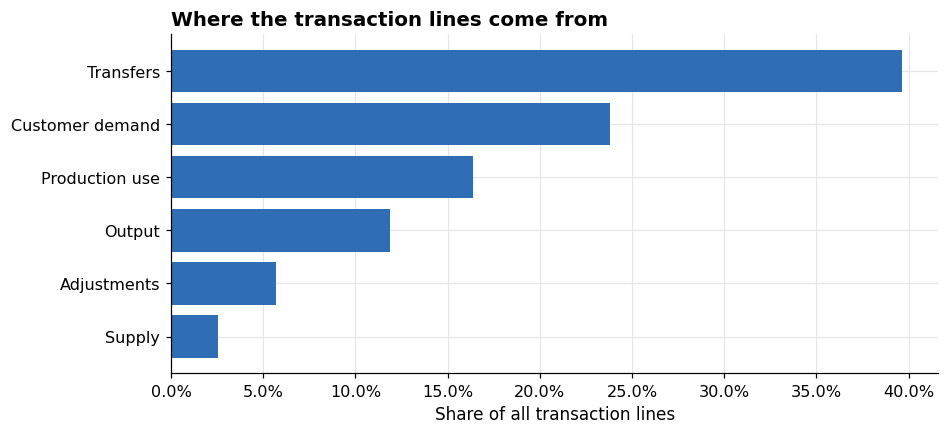

,net_quantity_change,total_quantity_received,total_quantity_issued,cost_posted_index,cost_adjustment_index,avg_cost_index,cost_volatility_index,had_cost_adjustment,total_transaction_lines,num_reference_types,unit_of_measure,first_transaction_date,last_transaction_date,receipt,issue,net,lines,d_receipt,d_issue,d_lines
ITEM-003619,"-1,698.00","131,496.00","133,194.00",18.60,79.60,48.60,44.00,1,3299,9,EA,2025-07-01,2026-06-30,"131,496.00","133,194.00","-1,698.00",3300,0.00,0.00,1


In [4]:
agg = mo.groupby("itemid").agg(receipt=("receipt_qty", "sum"), issue=("issue_qty", "sum"),
                                 net=("net_qty", "sum"), lines=("transaction_count", "sum"))
rec = yr.set_index("item_id").join(agg, how="outer")
rec["d_receipt"] = (rec.total_quantity_received - rec.receipt).abs()
rec["d_issue"] = (rec.total_quantity_issued - rec.issue).abs()
rec["d_lines"] = (rec.total_transaction_lines - rec.lines).abs()
mismatch = rec[(rec.d_receipt > 0.01) | (rec.d_issue > 0.01) | (rec.d_lines > 0) | rec.lines.isna() | rec.total_transaction_lines.isna()]
print(f"Items reconciled: {len(rec):,} | exceptions: {len(mismatch):,}")
TABLES["recon_exceptions"] = mismatch.reset_index()

# movement mix by reference group (lines are unit-free, so they can be added)
mix = mo.groupby("ref_group").transaction_count.sum().sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(mix.index, mix.values / mix.sum(), color=PALETTE[0])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title("Where the transaction lines come from")
ax.set_xlabel("Share of all transaction lines")
save(fig, "00_reference_mix")
mismatch.head(10)

---
# Q1. Which products barely move, which are falling, and which are unpredictable?
We look at each stocked product's **usage** month by month: what customers ordered plus what production used. A month with no record counts as zero. Each product is then put in one group:

* **Not used all year** - no movement at all.
* **Rarely used** - used in 3 months or fewer, or not used at all in the last quarter.
* **Usage falling** - used regularly, but usage dropped steadily, ending the year well below where it started.
* **Unpredictable** - used regularly, but monthly usage swings by more than its own normal month.
* **Healthy** - none of the above.

In [5]:
dem = (mo_stock[mo_stock.reference.isin(DEMAND_REFS)]
       .groupby(["itemid", "movement_month"]).issue_qty.sum()
       .unstack().reindex(index=STOCK_ITEMS, columns=MONTHS).fillna(0))
dem.columns = MONTH_LABELS

def robust_slope(row):
    y = row.to_numpy(float)
    if (y > 0).sum() < DECLINE_MIN_ACTIVE:
        return np.nan
    return stats.theilslopes(y, np.arange(len(y)))[0]

q1 = pd.DataFrame(index=dem.index)
q1["months_active"] = (dem > 0).sum(axis=1)
q1["total_demand"] = dem.sum(axis=1)
q1["mean"] = dem.mean(axis=1)
q1["cv"] = dem.std(axis=1, ddof=0) / q1["mean"]
nz = dem.where(dem > 0)
q1["cv2_nonzero"] = (nz.std(axis=1, ddof=0) / nz.mean(axis=1)) ** 2
q1["adi"] = 12 / q1["months_active"].replace(0, np.nan)
q1["slope"] = dem.apply(robust_slope, axis=1)
q1["slope_pct_per_month"] = q1["slope"] / q1["mean"]
h1, h2 = dem.iloc[:, :6].sum(axis=1), dem.iloc[:, 6:].sum(axis=1)
q1["h2_vs_h1"] = h2 / h1.replace(0, np.nan)

q1 = q1.join(yr.set_index("item_id")[["total_transaction_lines", "last_transaction_date",
                                       "cost_volatility_index", "cost_posted_index", "unit_of_measure"]])
q1 = q1.join(pm.set_index("product_id")[["product_name", "product_category", "lifecycle", "shelf_life", "ship_group_id"]])
q1["any_movement"] = q1.index.isin(mo.itemid)
q1["days_since_last_move"] = (pd.Timestamp("2026-06-30") - q1["last_transaction_date"]).dt.days

line_p10 = q1.loc[q1.any_movement, "total_transaction_lines"].quantile(0.10)
q1["non_moving"] = ~q1.any_movement
q1["barely_moves"] = q1.any_movement & (
    (q1.months_active <= SLOW_MAX_ACTIVE_MONTHS)
    | (q1.last_transaction_date < SLOW_RECENCY_CUTOFF)
    | (q1.total_transaction_lines <= line_p10))
q1["declining"] = ((q1.months_active >= DECLINE_MIN_ACTIVE)
                   & (q1.slope_pct_per_month < DECLINE_SLOPE_PCT)
                   & (q1.h2_vs_h1 < DECLINE_HALF_RATIO))
q1["volatile_demand"] = (q1.months_active >= VOLATILE_MIN_ACTIVE) & (q1.cv > VOLATILE_CV)
q1["volatile_cost"] = q1.cost_volatility_index > VOLATILE_COST_INDEX
q1["expiry_risk"] = q1.days_since_last_move > q1.shelf_life

# Syntetos-Boylan demand classes
def sbc(r):
    if r.months_active == 0:
        return "No demand"
    if r.adi < 1.32:
        return "Smooth" if r.cv2_nonzero < 0.49 else "Erratic"
    return "Intermittent" if r.cv2_nonzero < 0.49 else "Lumpy"
q1["demand_class"] = q1.apply(sbc, axis=1)

seg_cols = ["non_moving", "barely_moves", "declining", "volatile_demand", "volatile_cost", "expiry_risk"]
summary = q1.groupby("lifecycle")[seg_cols].sum().astype(int)
summary.loc["TOTAL"] = summary.sum()
TABLES["q1_item_metrics"] = q1.reset_index(names="item_id")
TABLES["q1_segment_by_lifecycle"] = summary.reset_index()
summary

,non_moving,barely_moves,declining,volatile_demand,volatile_cost,expiry_risk
lifecycle,,,,,,
End of life,55,239,119,108,37,20
In design,70,0,0,0,0,0
Obsolete,660,80,2,8,8,28
Operational,1314,526,169,358,618,247
TOTAL,2099,845,290,474,663,295


### Shared helpers for the simple charts

In [6]:
GOOD, WARN, BAD, CALM, INK, QUIET = "#3C9D74", "#E0B13A", ACCENT, "#7FA7D1", "#222222", "#666666"

def plain_axes(ax):
    """Strip chart furniture: no grid, no frame, no x ticks; direct labels do the work."""
    ax.grid(False)
    for side in ("top", "right", "bottom"):
        ax.spines[side].set_visible(False)
    ax.set_xticks([])
    ax.tick_params(axis="y", length=0, labelsize=11.5)

def pct(a, b):
    return f"{a / b:.0%}" if b else "-"

def short(name, n=38):
    name = str(name)
    return name if len(name) <= n else name[:n - 1] + "…"

ACTIVE_STATES = ["Operational", "In design", "(blank)"]
q1["active"] = q1.lifecycle.isin(ACTIVE_STATES)
status = pd.Series("Healthy", index=q1.index)
status[q1.volatile_demand] = "Unpredictable"
status[q1.declining] = "Usage falling"
status[q1.barely_moves] = "Rarely used"
status[q1.non_moving] = "Not used all year"
q1["status"] = status

### Q1 chart 1: where our stocked products stand (donut chart)
Each product sits in exactly one group, so the slices add up to every stocked product.

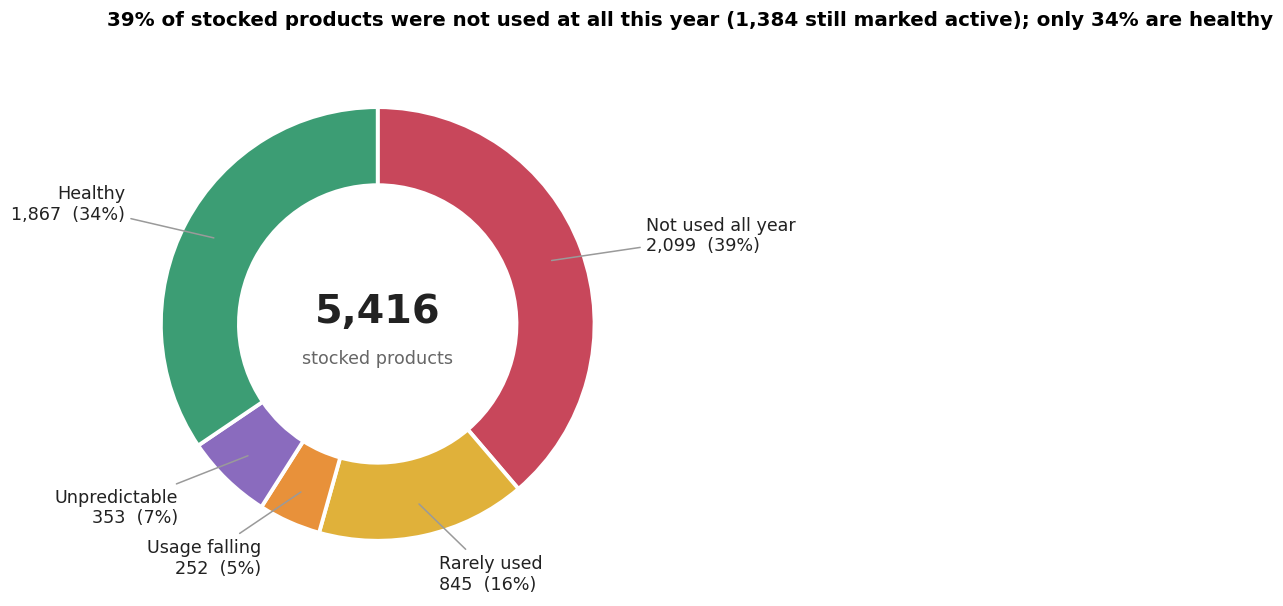

active,True,False
status,,
Not used all year,1384,715
Rarely used,526,319
Usage falling,159,93
Unpredictable,312,41
Healthy,1769,98


In [7]:
ORDER = ["Not used all year", "Rarely used", "Usage falling", "Unpredictable", "Healthy"]
COL = {"Not used all year": BAD, "Rarely used": WARN, "Usage falling": "#E8913A", "Unpredictable": "#8A6BBE", "Healthy": GOOD}
tab = (q1.groupby(["status", "active"]).size().unstack(fill_value=0)
         .reindex(index=ORDER, columns=[True, False]).fillna(0).astype(int))
total = len(q1)
sizes = tab.sum(axis=1)
fig, ax = plt.subplots(figsize=(10.5, 6.4))
wedges, _ = ax.pie(sizes, colors=[COL[s] for s in ORDER], startangle=90, counterclock=False,
                   wedgeprops=dict(width=0.36, edgecolor="white", linewidth=2.5))
ax.text(0, 0.06, f"{total:,}", ha="center", va="center", fontsize=26, weight="bold", color=INK)
ax.text(0, -0.16, "stocked products", ha="center", va="center", fontsize=11.5, color=QUIET)
for w, s, n in zip(wedges, ORDER, sizes):
    ang = np.deg2rad((w.theta2 + w.theta1) / 2)
    x, y = np.cos(ang), np.sin(ang)
    ax.annotate(f"{s}\n{n:,}  ({n / total:.0%})", xy=(0.84 * x, 0.84 * y), xytext=(1.32 * x, 1.18 * y),
                ha="left" if x >= 0 else "right", va="center", fontsize=11.5, color=INK,
                arrowprops=dict(arrowstyle="-", color="#9A9A9A", lw=1))
ax.set_aspect("equal")
ax.set_title(f"{pct(sizes['Not used all year'], total)} of stocked products were not used at all this year "
             f"({tab.loc['Not used all year', True]:,} still marked active); only {pct(sizes['Healthy'], total)} are healthy",
             fontsize=13, pad=18)
save(fig, "q1_1_where_products_stand")
TABLES["q1_status_summary"] = tab.rename(columns={True: "still_active", False: "phasing_out"}).reset_index()
tab

### Q1 chart 2: the trend for falling products (line chart)
The typical falling product's monthly usage, against the typical healthy product. Each product is scaled so its July to December average = 100; the shaded band is the middle half of falling products.

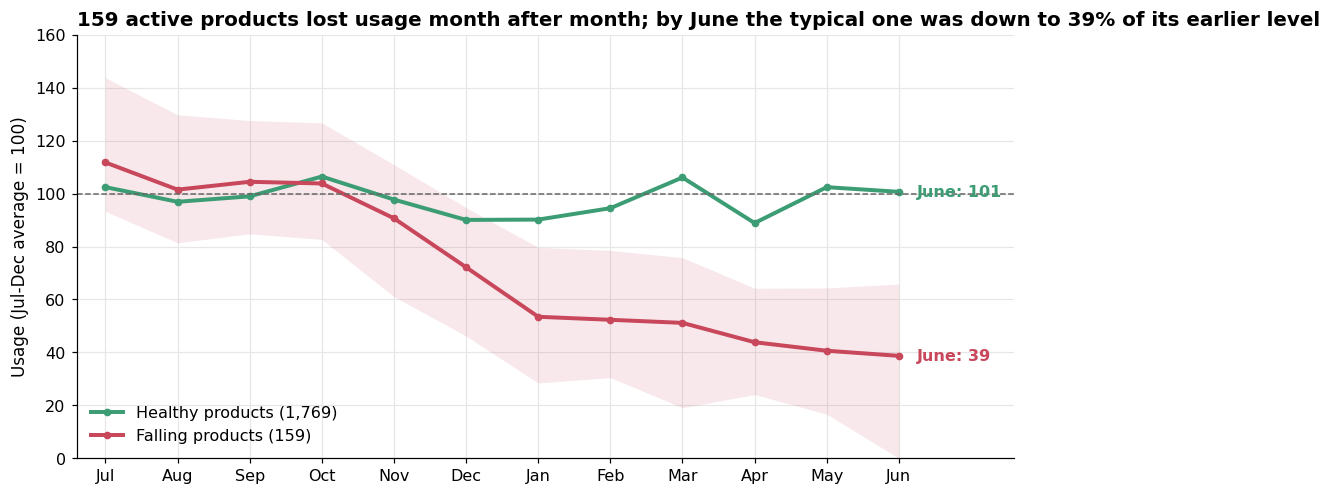

In [8]:
falling = q1[(q1.status == "Usage falling") & q1.active].copy()
TABLES["q1_falling_products"] = (falling.reset_index(names="item_id")
    [["item_id", "product_name", "product_category", "months_active", "h2_vs_h1"]]
    .assign(drop_jan_jun_vs_jul_dec=lambda d: 1 - d.h2_vs_h1).sort_values("drop_jan_jun_vs_jul_dec", ascending=False))

def first_half_index(ids):
    d = dem.loc[ids]
    base = d.iloc[:, :6].mean(axis=1)
    return d[base > 0].div(base[base > 0], axis=0) * 100

f_idx = first_half_index(falling.index)
h_idx = first_half_index(q1.index[(q1.status == "Healthy") & q1.active])
x = np.arange(12)
fig, ax = plt.subplots(figsize=(11, 5))
ax.fill_between(x, f_idx.quantile(.25), f_idx.quantile(.75), color=BAD, alpha=.12, lw=0)
ax.plot(x, h_idx.median(), color=GOOD, lw=2.6, marker="o", ms=4, label=f"Healthy products ({len(h_idx):,})")
ax.plot(x, f_idx.median(), color=BAD, lw=2.6, marker="o", ms=4, label=f"Falling products ({len(f_idx):,})")
ax.axhline(100, color=QUIET, lw=1, ls="--")
end_f, end_h = f_idx.median().iloc[-1], h_idx.median().iloc[-1]
ax.annotate(f"June: {end_f:.0f}", (11, end_f), xytext=(12, 0), textcoords="offset points", va="center", color=BAD, weight="bold")
ax.annotate(f"June: {end_h:.0f}", (11, end_h), xytext=(12, 0), textcoords="offset points", va="center", color=GOOD, weight="bold")
ax.set_xticks(x); ax.set_xticklabels([m[:3] for m in MONTH_LABELS]); ax.set_xlim(-0.4, 12.6)
ax.set_ylim(0, max(160, h_idx.median().max() * 1.2)); ax.set_ylabel("Usage (Jul-Dec average = 100)")
ax.legend(loc="lower left")
ax.set_title(f"{len(falling):,} active products lost usage month after month; by June the typical one "
             f"was down to {end_f:.0f}% of its earlier level", fontsize=13)
save(fig, "q1_2_falling_products")

### Q1 charts 3 to 5: unpredictable products
**"Unpredictable"** means an item's monthly usage swings by more than its own normal month: one month it doubles, the next it nearly stops. Only regularly used products are judged (not the rarely used or falling ones, which have their own groups), so every product is counted once.

Three charts, no statistics needed:
1. **What it looks like** (line chart): a steady product next to an unpredictable one, each month shown against its own normal month (100 = a normal month).
2. **How far usage swings, and why** (box plot and pie chart): the typical range of monthly usage for steady, variable and unpredictable products, and the plain reason behind the unpredictable ones.
3. **Two different risks** (scatter plot): unpredictable quantity (a planning problem) and unpredictable cost (a buying problem) mostly affect different products, so they need different owners.

In [9]:
# plain-language groups used by the three charts
eligible = q1[q1.status.isin(["Unpredictable", "Healthy"])].copy()   # regularly used, not rare or falling
eligible["pattern"] = pd.cut(eligible.cv, [-np.inf, 0.5, np.inf], labels=["Steady", "Variable"]).astype(str)
eligible.loc[eligible.status == "Unpredictable", "pattern"] = "Unpredictable"

def plain_reason(r):
    if r.lifecycle in ("End of life", "Obsolete"):
        return "Being phased out"
    if r.demand_class in ("Intermittent", "Lumpy"):
        return "Ordered on and off"
    return "Ordered monthly,\nbut amounts jump"
unpred = eligible[eligible.status == "Unpredictable"].copy()
unpred["reason"] = unpred.apply(plain_reason, axis=1)

STEADY_C, VAR_C, UNPRED_C = "#3C9D74", "#E0B13A", ACCENT
def short(name, n=38):
    name = str(name)
    return name if len(name) <= n else name[:n - 1] + "…"

### Q1 chart 3: what an unpredictable product looks like (line chart)
Two real products on one chart, each scaled so its normal month = 100.

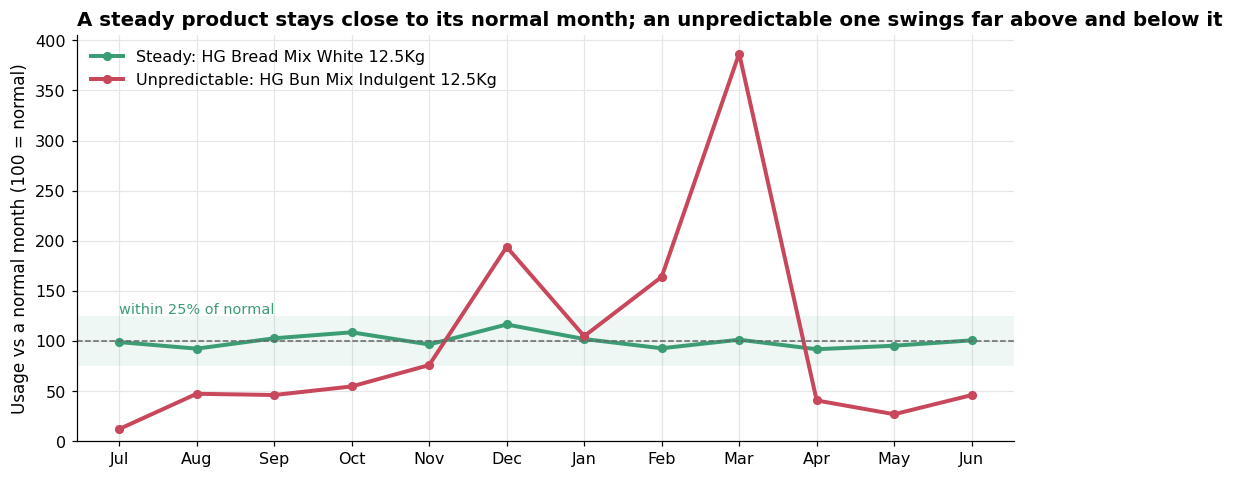

In [10]:
op = eligible[eligible.lifecycle == "Operational"]
steady_pool = op[(op.months_active == 12) & (op.cv < 0.25)]
jumpy_pool = unpred[(unpred.lifecycle == "Operational") & (unpred.months_active >= 8)]
if steady_pool.empty or jumpy_pool.empty:
    print("No suitable example pair; skip this chart.")
else:
    steady_item = steady_pool.sort_values("total_transaction_lines", ascending=False).index[0]
    jumpy_item = jumpy_pool.sort_values("total_transaction_lines", ascending=False).index[0]
    x = np.arange(12)
    fig, ax = plt.subplots(figsize=(11, 4.8))
    ax.axhspan(75, 125, color=GOOD, alpha=.08, lw=0)
    ax.text(0, 127, "within 25% of normal", fontsize=9.5, color=GOOD)
    for item, colr, lab in [(steady_item, STEADY_C, "Steady"), (jumpy_item, UNPRED_C, "Unpredictable")]:
        y = dem.loc[item].to_numpy(float) / dem.loc[item].mean() * 100
        ax.plot(x, y, color=colr, lw=2.6, marker="o", ms=5, label=f"{lab}: {short(q1.at[item, 'product_name'], 34)}")
    ax.axhline(100, color=QUIET, lw=1, ls="--")
    ax.set_xticks(x); ax.set_xticklabels([m[:3] for m in MONTH_LABELS])
    ax.set_ylim(0, None); ax.set_ylabel("Usage vs a normal month (100 = normal)")
    ax.legend(loc="upper left")
    ax.set_title("A steady product stays close to its normal month; an unpredictable one swings far above and below it", fontsize=13)
    save(fig, "q1_volatility_1_what_it_looks_like")

### Q1 chart 4: how far monthly usage swings (box plot), and why (pie chart)
Left: each box shows the middle half of months for that group of products, the line inside is the typical month, and the whiskers cover 9 months in 10. Right: the plain reason behind the unpredictable products.

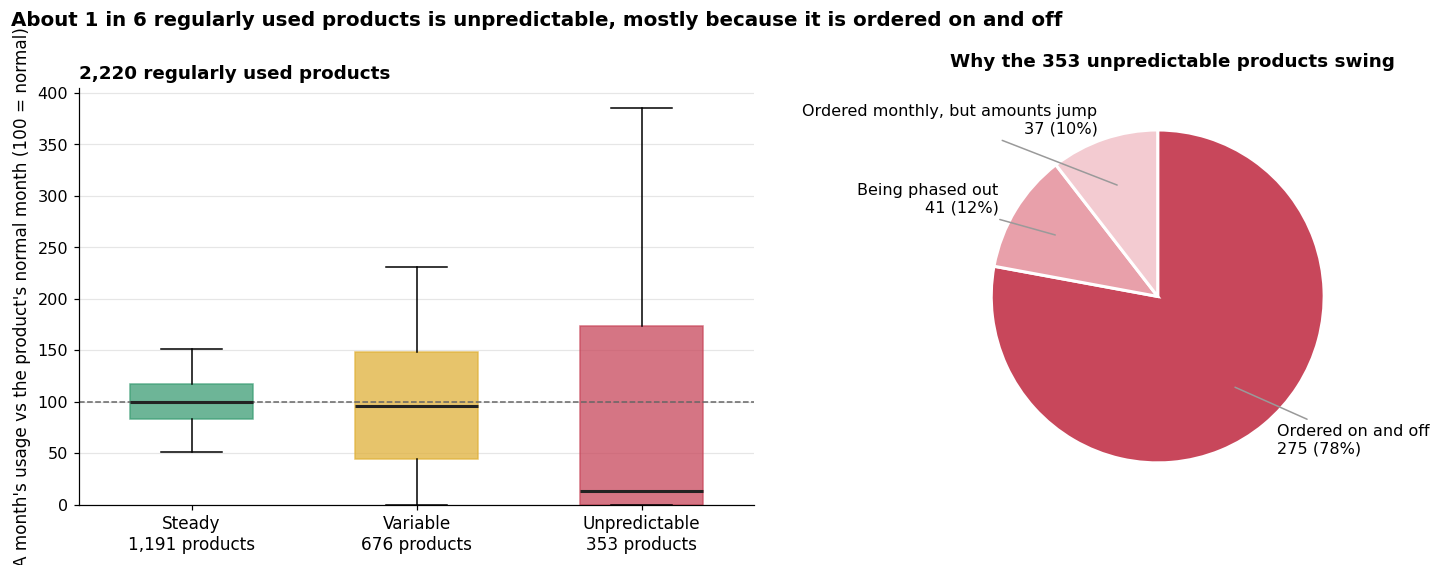

In [11]:
counts = eligible.pattern.value_counts().reindex(["Steady", "Variable", "Unpredictable"])
reasons = unpred.reason.value_counts()
groups = ["Steady", "Variable", "Unpredictable"]
data = []
for gname in groups:
    ids = eligible.index[eligible.pattern == gname]
    d = dem.loc[ids]
    m = d.mean(axis=1)
    data.append((d[m > 0].div(m[m > 0], axis=0) * 100).to_numpy().ravel())
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13.5, 5.2), gridspec_kw={"width_ratios": [1.35, 1]})
bp = a1.boxplot(data, whis=(5, 95), showfliers=False, patch_artist=True, widths=.55,
                medianprops=dict(color=INK, lw=2))
for patch, colr in zip(bp["boxes"], [STEADY_C, VAR_C, UNPRED_C]):
    patch.set_facecolor(colr); patch.set_alpha(.75); patch.set_edgecolor(colr)
a1.axhline(100, color=QUIET, lw=1, ls="--")
a1.set_xticks([1, 2, 3]); a1.set_xticklabels([f"{gname}\n{counts[gname]:,} products" for gname in groups], fontsize=11)
a1.set_ylabel("A month's usage vs the product's normal month (100 = normal)")
a1.set_ylim(0, None); a1.grid(axis="x", visible=False)
a1.set_title(f"{counts.sum():,} regularly used products", fontsize=12)
pie_cols = [UNPRED_C, "#E8A0AA", "#F3CBD1"]
w, _ = a2.pie(reasons.values, colors=pie_cols[:len(reasons)], startangle=90, counterclock=False,
              wedgeprops=dict(edgecolor="white", linewidth=2))
for wedge, lab, n in zip(w, reasons.index, reasons.values):
    ang = np.deg2rad((wedge.theta2 + wedge.theta1) / 2)
    xx, yy = np.cos(ang), np.sin(ang)
    a2.annotate(f"{lab.replace(chr(10), ' ')}\n{n:,} ({n / reasons.sum():.0%})", xy=(.7 * xx, .7 * yy), xytext=(1.12 * xx, 1.12 * yy),
                ha="left" if xx >= 0 else "right", va="center", fontsize=10.5, arrowprops=dict(arrowstyle="-", color="#9A9A9A"))
a2.set_aspect("equal"); a2.set_title(f"Why the {len(unpred):,} unpredictable products swing", fontsize=12, pad=14)
fig.suptitle(f"About 1 in {round(counts.sum() / counts['Unpredictable'])} regularly used products is unpredictable, "
             "mostly because it is ordered on and off", x=0.01, ha="left", weight="bold", fontsize=13)
fig.tight_layout()
save(fig, "q1_volatility_2_how_many_and_why")

### Q1 chart 5: two different risks, two different owners (scatter plot)
Each dot is one regularly used product: further right = its quantity swings more; higher up = its cost swings more. The dashed lines mark where a swing counts as unpredictable.

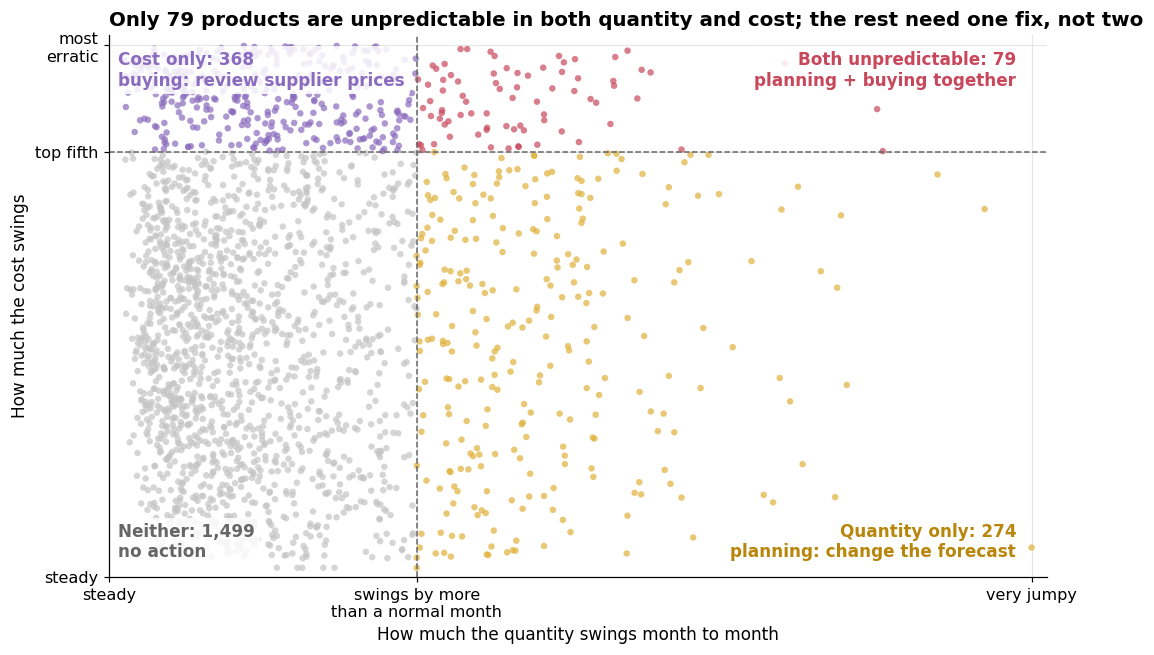

In [12]:
qty = eligible.status.eq("Unpredictable")
cost = eligible.volatile_cost.fillna(False).astype(bool)
grid = {("Q", "C"): int((qty & cost).sum()), ("Q", "-"): int((qty & ~cost).sum()),
        ("-", "C"): int((~qty & cost).sum()), ("-", "-"): int((~qty & ~cost).sum())}
quad_col = np.select([qty & cost, qty & ~cost, ~qty & cost], [UNPRED_C, VAR_C, "#8A6BBE"], default="#C4C4C4")
xs = eligible.cv.clip(upper=3); ys = eligible.cost_volatility_index.fillna(0)
fig, ax = plt.subplots(figsize=(11, 6.4))
ax.scatter(xs, ys, c=quad_col, s=18, alpha=.7, edgecolor="none")
ax.axvline(VOLATILE_CV, color=QUIET, ls="--", lw=1); ax.axhline(VOLATILE_COST_INDEX, color=QUIET, ls="--", lw=1)
label_spots = [(("Q", "C"), 2.95, 99, "right", "Both unpredictable", "planning + buying together", UNPRED_C),
               (("Q", "-"), 2.95, 3, "right", "Quantity only", "planning: change the forecast", "#B8860B"),
               (("-", "C"), 0.03, 99, "left", "Cost only", "buying: review supplier prices", "#8A6BBE"),
               (("-", "-"), 0.03, 3, "left", "Neither", "no action", QUIET)]
for key, lx, ly, ha, head, act, colr in label_spots:
    ax.text(lx, ly, f"{head}: {grid[key]:,}\n{act}", ha=ha, va="top" if ly > 50 else "bottom", fontsize=11,
            weight="bold", color=colr, bbox=dict(facecolor="white", edgecolor="none", alpha=.85, pad=3))
ax.set_xlim(0, 3.05); ax.set_ylim(0, 102)
ax.set_xticks([0, VOLATILE_CV, 3]); ax.set_xticklabels(["steady", "swings by more\nthan a normal month", "very jumpy"])
ax.set_yticks([0, VOLATILE_COST_INDEX, 100]); ax.set_yticklabels(["steady", "top fifth", "most\nerratic"])
ax.set_xlabel("How much the quantity swings month to month"); ax.set_ylabel("How much the cost swings")
ax.set_title(f"Only {grid[('Q', 'C')]:,} products are unpredictable in both quantity and cost; "
             "the rest need one fix, not two", fontsize=13)
save(fig, "q1_volatility_3_two_risks")
TABLES["q1_volatility_plain"] = (unpred.reset_index(names="item_id")
    [["item_id", "product_name", "product_category", "lifecycle", "months_active", "reason", "volatile_cost"]]
    .sort_values(["reason", "product_category"]))

### Q1 key messages

In [13]:
g = q1.status.value_counts()
unused = q1.status == "Not used all year"
msgs = [
    f"{g['Not used all year']:,} of {len(q1):,} stocked products ({pct(g['Not used all year'], len(q1))}) were not used at all this year; "
    f"{int((unused & q1.active).sum()):,} of them are still marked active. Action: switch them off in the system after a quick check.",
    f"Another {g['Rarely used']:,} were used only rarely. {int((q1.any_movement & q1.expiry_risk).sum()):,} products have sat unused "
    "for longer than their shelf life, so stock may need writing off. Action: stop reordering, sell down or make to order.",
    f"{len(falling):,} active products are steadily losing usage; the typical one is used {1 - falling.h2_vs_h1.median():.0%} less "
    "in the second half of the year. Action: ask sales and planning whether each is being replaced or losing customers.",
    f"{g['Unpredictable']:,} regularly used products are unpredictable, mostly because they are ordered on and off. "
    f"Only {grid[('Q', 'C')]:,} are unpredictable in both quantity and cost. "
    "Action: planning changes how on-and-off products are forecast; buying reviews prices for the cost-only ones.",
    f"{g['Healthy']:,} products ({pct(g['Healthy'], len(q1))}) are healthy: used regularly and predictably.",
]
for m in msgs:
    print("\u2022", m, "\n")

• 2,099 of 5,416 stocked products (39%) were not used at all this year; 1,384 of them are still marked active. Action: switch them off in the system after a quick check. 

• Another 845 were used only rarely. 295 products have sat unused for longer than their shelf life, so stock may need writing off. Action: stop reordering, sell down or make to order. 

• 159 active products are steadily losing usage; the typical one is used 46% less in the second half of the year. Action: ask sales and planning whether each is being replaced or losing customers. 

• 353 regularly used products are unpredictable, mostly because they are ordered on and off. Only 79 are unpredictable in both quantity and cost. Action: planning changes how on-and-off products are forecast; buying reviews prices for the cost-only ones. 

• 1,867 products (34%) are healthy: used regularly and predictably. 



---
# Q2. When a number looks unusual, is it really unusual, and what caused it?
A big number is not necessarily unusual: bulk flour or grain moves in big numbers every month. So each product's monthly movement at each site is compared with **that same product's normal month at that site**. A month counts as **unusual** only when it is far outside that product's own normal range.

Then we ask three plain questions about each unusual month: **what caused it** (a customer order, a stock correction, a transfer?), **where it happened**, and **whether it hit every site at once** (which would point to a company-wide event such as the year-end stocktake).

In [14]:
mo_stock["gross_qty"] = mo_stock.receipt_qty + mo_stock.issue_qty
g = mo_stock.groupby(["itemid", "site_id", "unitid", "movement_month"]).gross_qty.sum()
wide = g.unstack("movement_month").reindex(columns=MONTHS).fillna(0)
logw = np.log1p(wide)
med = logw.median(axis=1)
mad = (logw.sub(med, axis=0)).abs().median(axis=1)
meanad = (logw.sub(logw.mean(axis=1), axis=0)).abs().mean(axis=1)
scale = (1.4826 * mad).where(mad > 0, 1.2533 * meanad)      # fall back when MAD = 0
scale = scale.clip(lower=Z_SCALE_FLOOR)                     # a 1-unit wobble on a flat series is not an anomaly
z = logw.sub(med, axis=0).div(scale.replace(0, np.nan), axis=0).fillna(0)
active_months = (wide > 0).sum(axis=1)
z[active_months < 4] = np.nan                                 # too sparse to judge

pts = (pd.DataFrame({"qty": wide.stack(), "z_local": z.stack()})
         .reset_index().rename(columns={"level_4": "movement_month"}))
pts.columns = ["itemid", "site_id", "unitid", "movement_month", "qty", "z_local"]
pts = pts[pts.qty > 0].copy()

# baseline: whole dataset (percentile within the same unit)
pts["pct_global"] = pts.groupby("unitid").qty.rank(pct=True)
# baseline: same item at other sites, same month
other = pts.groupby(["itemid", "movement_month"]).z_local.agg(["sum", "count"])
pts = pts.join(other, on=["itemid", "movement_month"])
pts["z_other_sites"] = (pts["sum"] - pts.z_local.fillna(0)) / (pts["count"] - 1).replace(0, np.nan)
pts = pts.drop(columns=["sum", "count"])
# baseline: time period
pts["is_local"] = pts.z_local > ANOMALY_Z
pts["is_global"] = pts.pct_global > GLOBAL_PCT
month_rate = pts.groupby("movement_month").is_local.mean()
period_wide = month_rate > 2 * month_rate.median()
pts["period_wide"] = pts.movement_month.map(period_wide)
pts["site_specific"] = pts.is_local & (pts.z_other_sites.fillna(0) < 1)

def quadrant(r):
    if r.is_local and r.is_global: return "Unusual for SKU and large"
    if r.is_local: return "Unusual for this SKU only"
    if r.is_global: return "Large vs dataset only"
    return "Normal"
pts["anomaly_type"] = pts.apply(quadrant, axis=1)

# what drove the point: the reference type with the biggest gross movement that month
drv = (mo_stock.groupby(["itemid", "site_id", "movement_month", "reference"]).gross_qty.sum()
       .reset_index().sort_values("gross_qty").drop_duplicates(["itemid", "site_id", "movement_month"], keep="last"))
pts = pts.merge(drv[["itemid", "site_id", "movement_month", "reference"]].rename(columns={"reference": "main_reference"}),
                on=["itemid", "site_id", "movement_month"], how="left")
pts["main_ref_group"] = pts.main_reference.map(REF_GROUP)

TABLES["q2_anomalies"] = pts[pts.is_local].sort_values("z_local", ascending=False)
print(pts.anomaly_type.value_counts())
print("\nLocal anomalies by what drove them:\n", pts[pts.is_local].main_ref_group.value_counts())
print("\nMonths with a period-wide spike rate:", [m.strftime("%b %Y") for m in period_wide[period_wide].index])

anomaly_type
Normal                       81598
Large vs dataset only          825
Unusual for this SKU only      733
Unusual for SKU and large       11
Name: count, dtype: int64

Local anomalies by what drove them:
 main_ref_group
Adjustments        278
Transfers          200
Supply             170
Output              45
Customer demand     35
Production use      16
Name: count, dtype: int64

Months with a period-wide spike rate: []


### Q2 chart 1: what caused the unusual months (donut chart)
Red slices are internal: stock corrections and moves between sites. Blue slices are outside or production activity.

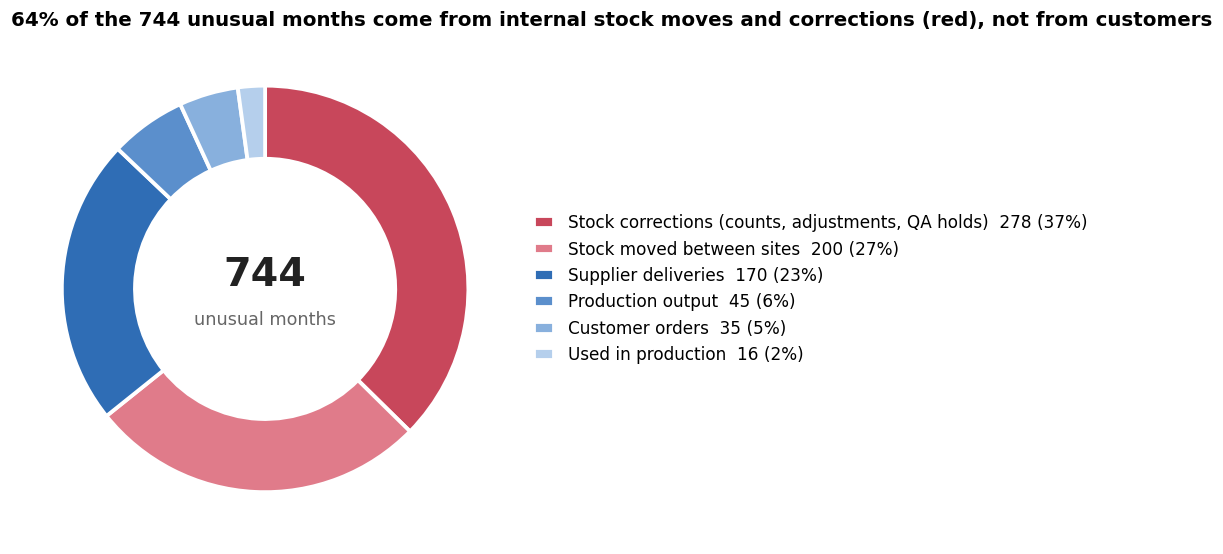

In [15]:
PLAIN_CAUSE = {
    "Adjustments": "Stock corrections (counts, adjustments, QA holds)",
    "Transfers": "Stock moved between sites",
    "Supply": "Supplier deliveries",
    "Output": "Production output",
    "Customer demand": "Customer orders",
    "Production use": "Used in production",
}
INTERNAL = ["Adjustments", "Transfers"]
unusual = pts[pts.is_local].copy()
unusual["cause"] = unusual.main_ref_group.map(PLAIN_CAUSE).fillna("Other")
c = unusual.cause.value_counts()
internal_share = unusual.main_ref_group.isin(INTERNAL).mean()
internal_labels = {PLAIN_CAUSE[k] for k in INTERNAL}
reds, blues = iter(["#C8475B", "#E07B8A"]), iter(["#2F6DB5", "#5B8FCC", "#88B0DD", "#B5CFEC", "#DCE8F6"])
cols = [next(reds) if k in internal_labels else next(blues) for k in c.index]
fig, ax = plt.subplots(figsize=(11.5, 6))
w, _ = ax.pie(c.values, colors=cols, startangle=90, counterclock=False,
              wedgeprops=dict(width=0.36, edgecolor="white", linewidth=2.5))
ax.text(0, 0.07, f"{len(unusual):,}", ha="center", va="center", fontsize=26, weight="bold", color=INK)
ax.text(0, -0.15, "unusual months", ha="center", va="center", fontsize=11.5, color=QUIET)
ax.legend(w, [f"{k}  {v:,} ({v / c.sum():.0%})" for k, v in c.items()], loc="center left",
          bbox_to_anchor=(1.0, 0.5), fontsize=11, handlelength=1.2)
ax.set_aspect("equal")
ax.set_title(f"{internal_share:.0%} of the {len(unusual):,} unusual months come from internal stock moves and "
             "corrections (red), not from customers", fontsize=13)
save(fig, "q2_1_what_caused_unusual_months")
TABLES["q2_unusual_months"] = unusual.sort_values("z_local", ascending=False)

### Q2 chart 2: one unusual month, in context (line chart)
The strongest example: one product at one site over the year. The red point is the unusual month; the dashed line is its normal month.

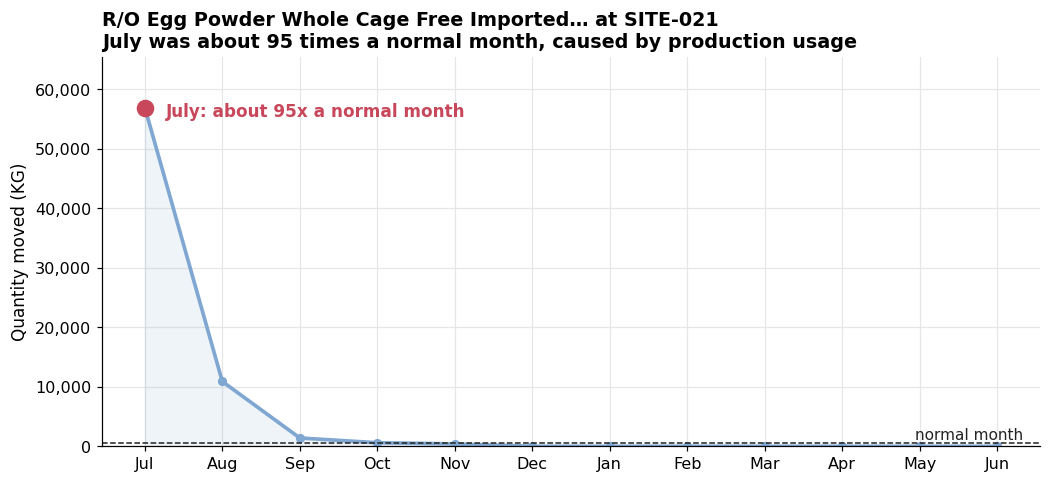

In [16]:
if unusual.empty:
    print("No unusual months found.")
else:
    r = unusual.sort_values("z_local", ascending=False).iloc[0]
    key = (r.itemid, r.site_id, r.unitid)
    yv = wide.loc[key].to_numpy(float)
    normal = np.median(yv[yv > 0]) if (yv > 0).any() else 0
    i = MONTHS.get_loc(r.movement_month)
    fig, ax = plt.subplots(figsize=(11, 4.6))
    ax.plot(range(12), yv, color=CALM, lw=2.4, marker="o", ms=5)
    ax.fill_between(range(12), 0, yv, color=CALM, alpha=.12)
    ax.scatter([i], [yv[i]], color=BAD, s=110, zorder=3)
    ax.axhline(normal, color=INK, lw=1, ls="--")
    ax.text(11.4, normal, "normal month ", va="bottom", ha="right", fontsize=10, color=INK)
    ax.set_xticks(range(12)); ax.set_xticklabels([m[:3] for m in MONTH_LABELS])
    ax.set_ylabel(f"Quantity moved ({r.unitid})"); ax.set_ylim(0, yv.max() * 1.15)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    times = r.qty / normal if normal else np.nan
    CAUSE_PHRASE = {"Adjustments": "a stock correction", "Transfers": "a stock transfer", "Supply": "a supplier delivery",
                    "Output": "production output", "Customer demand": "customer orders", "Production use": "production usage"}
    ax.annotate(f"{r.movement_month:%B}: about {times:,.0f}x a normal month", (i, yv[i]), xytext=(14, -6),
                textcoords="offset points", color=BAD, weight="bold", fontsize=11, ha="left" if i < 8 else "right")
    name = short(pm.set_index("product_id").at[r.itemid, "product_name"], 40)
    ax.set_title(f"{name} at {r.site_id}\n{r.movement_month:%B} was about {times:,.0f} times a normal month, "
                 f"caused by {CAUSE_PHRASE.get(r.main_ref_group, 'other activity')}", fontsize=12.5)
    save(fig, "q2_2_unusual_month_example")

### Q2 chart 3: where the unusual months happen (bar chart)
The 10 sites with the most unusual months.

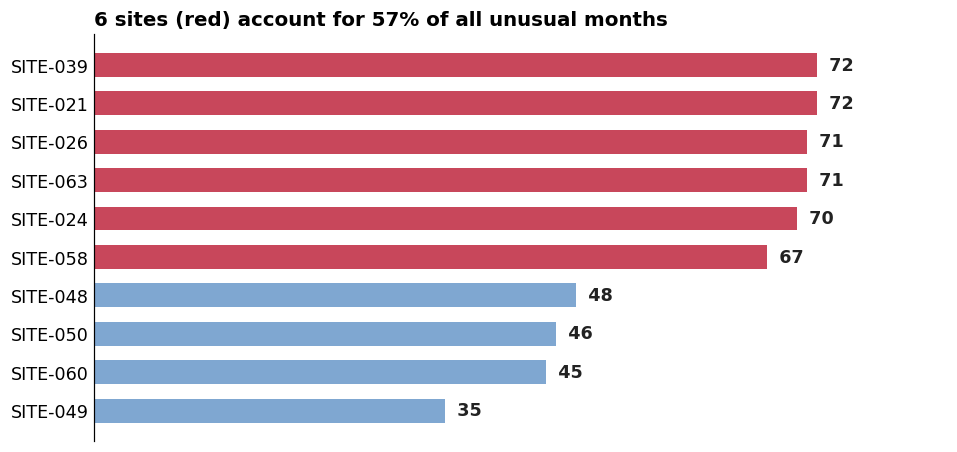

In [17]:
by_site_unusual = unusual.site_id.value_counts()
top10 = by_site_unusual.head(10).sort_values()
lead = by_site_unusual[by_site_unusual >= 0.8 * by_site_unusual.max()]      # sites close to the highest count
lead_share = lead.sum() / by_site_unusual.sum() if len(by_site_unusual) else 0
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(top10.index, top10.values, color=[BAD if s in lead.index else CALM for s in top10.index], height=.62)
for i, v in enumerate(top10.values):
    ax.text(v, i, f"  {v:,}", va="center", fontsize=11.5, weight="bold", color=INK)
plain_axes(ax); ax.set_xlim(0, top10.max() * 1.18)
ax.set_title(f"{len(lead)} sites (red) account for {lead_share:.0%} of all unusual months", fontsize=13)
save(fig, "q2_3_where_unusual_months_happen")
TABLES["q2_unusual_by_site"] = by_site_unusual.rename("unusual_months").reset_index()

### Q2 chart 4: unusual months through the year (trend chart)
How many unusual months were recorded in each calendar month, split into internal causes and everything else.

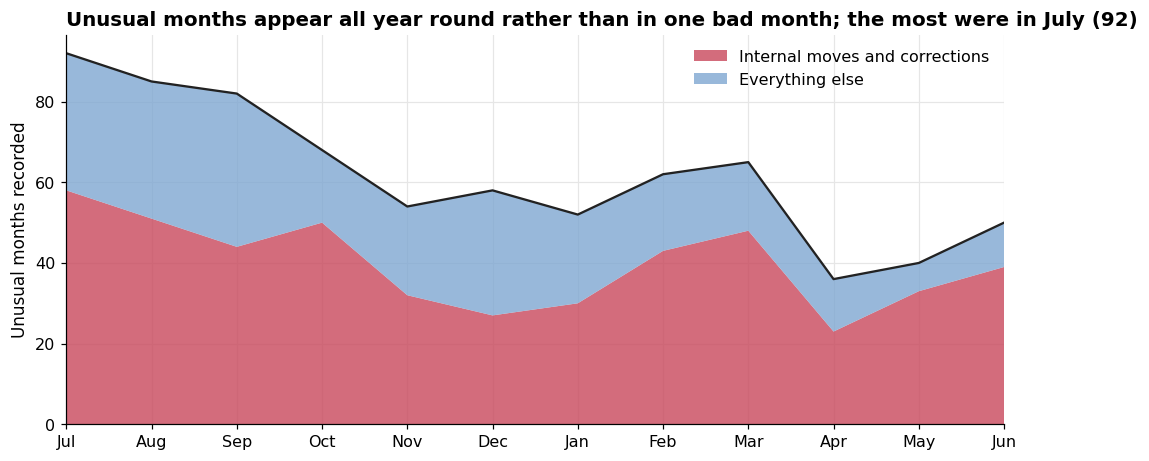

In [18]:
by_month = (unusual.assign(kind=np.where(unusual.main_ref_group.isin(INTERNAL), "Internal moves and corrections", "Everything else"))
            .groupby(["movement_month", "kind"]).size().unstack(fill_value=0).reindex(MONTHS, fill_value=0))
peak_m = by_month.sum(axis=1).idxmax()
fig, ax = plt.subplots(figsize=(11, 4.6))
x = np.arange(12)
ax.stackplot(x, by_month.get("Internal moves and corrections", 0), by_month.get("Everything else", 0),
             colors=[BAD, CALM], alpha=.8, labels=["Internal moves and corrections", "Everything else"])
ax.plot(x, by_month.sum(axis=1), color=INK, lw=1.5)
ax.set_xticks(x); ax.set_xticklabels([m[:3] for m in MONTH_LABELS]); ax.set_xlim(0, 11)
ax.set_ylabel("Unusual months recorded"); ax.legend(loc="upper right")
ax.set_title(f"Unusual months appear all year round rather than in one bad month; the most were in "
             f"{peak_m:%B} ({by_month.loc[peak_m].sum():,})", fontsize=13)
save(fig, "q2_4_unusual_months_by_month")
TABLES["q2_unusual_by_month"] = by_month.reset_index()

### Q2 key messages

In [19]:
big_normal = int((pts.anomaly_type == "Large vs dataset only").sum())
months_hit = [m.strftime("%B %Y") for m in period_wide[period_wide].index]
msgs = [
    f"We checked {len(pts):,} monthly records (one product, at one site, in one month). {len(unusual):,} were truly unusual for that product; "
    f"another {big_normal:,} looked big but were normal for the product (bulk items), so they need no action.",
    f"{internal_share:.0%} of unusual months were caused by internal stock moves and corrections, "
    f"and only {(unusual.main_ref_group == 'Customer demand').mean():.0%} by customer orders. "
    "Action: most of these are process issues for site operations, not demand signals for planning.",
    f"{len(lead)} sites ({', '.join(lead.index)}) account for {lead_share:.0%} of unusual months. "
    "Action: review stocktake and transfer practices at those sites first.",
    ("No month hit every site at once, so there is no company-wide event distorting the year."
     if not months_hit else f"{', '.join(months_hit)} affected many sites at once (likely a company-wide event such as stocktake); "
     "exclude those corrections from forecasting history."),
    "Action: run this check every month so unusual records are caught when they happen, not at year end.",
]
for m in msgs:
    print("•", m, "\n")

• We checked 83,167 monthly records (one product, at one site, in one month). 744 were truly unusual for that product; another 825 looked big but were normal for the product (bulk items), so they need no action. 

• 64% of unusual months were caused by internal stock moves and corrections, and only 5% by customer orders. Action: most of these are process issues for site operations, not demand signals for planning. 

• 6 sites (SITE-021, SITE-039, SITE-063, SITE-026, SITE-024, SITE-058) account for 57% of unusual months. Action: review stocktake and transfer practices at those sites first. 

• No month hit every site at once, so there is no company-wide event distorting the year. 

• Action: run this check every month so unusual records are caught when they happen, not at year end. 



---
# Q3. Is activity spread evenly, or do a few products do most of the work?
**Activity** = the number of stock transactions a product had in the year. It works for every product whatever its unit (kilos, cartons, each), so all products can be compared fairly.

We ask: how many products make up 80% of all activity, which product groups carry more than their share, and whether some sites depend on just a handful of products.

In [20]:
def lorenz(values):
    v = np.sort(np.asarray(values, float)); v = v[v > 0]
    cum = np.insert(np.cumsum(v) / v.sum(), 0, 0)
    share_items = np.linspace(0, 1, len(cum))
    return share_items, cum

def gini(values):
    v = np.sort(np.asarray(values, float)); v = v[v > 0]
    n = len(v)
    if n == 0: return np.nan
    return (2 * np.arange(1, n + 1) - n - 1).dot(v) / (n * v.sum())

def items_for_share(values, share=0.8):
    v = np.sort(np.asarray(values, float))[::-1]; v = v[v > 0]
    return int(np.searchsorted(np.cumsum(v) / v.sum(), share) + 1), len(v)

lines = yr.loc[yr.item_id.isin(STOCK_ITEMS)].set_index("item_id").total_transaction_lines
kg = yr.loc[yr.item_id.isin(STOCK_ITEMS) & (yr.unit_of_measure == "KG")].set_index("item_id")
kg_qty = kg.total_quantity_received + kg.total_quantity_issued

def top_share(v, p):
    v = np.sort(v[v > 0])[::-1]; k = max(1, int(round(len(v) * p)))
    return v[:k].sum() / v.sum()

conc = pd.DataFrame({
    "measure": ["Transaction lines (all items)", "Gross quantity (KG items)"],
    "items": [int((lines > 0).sum()), int((kg_qty > 0).sum())],
    "gini": [gini(lines), gini(kg_qty)],
    "top_1pct_share": [top_share(lines.to_numpy(), .01), top_share(kg_qty.to_numpy(), .01)],
    "top_5pct_share": [top_share(lines.to_numpy(), .05), top_share(kg_qty.to_numpy(), .05)],
    "top_20pct_share": [top_share(lines.to_numpy(), .20), top_share(kg_qty.to_numpy(), .20)],
    "items_for_80pct": [items_for_share(lines)[0], items_for_share(kg_qty)[0]],
})
TABLES["q3_concentration"] = conc
conc

,measure,items,gini,top_1pct_share,top_5pct_share,top_20pct_share,items_for_80pct
0,Transaction lines (all items),3317,0.83,0.27,0.58,0.87,457
1,Gross quantity (KG items),1341,0.95,0.50,0.85,0.98,51


### Q3 chart 1: a small share of products does most of the work (cumulative line chart)
Products are lined up from busiest to quietest. The line shows how much of all activity has been reached as each product is added.

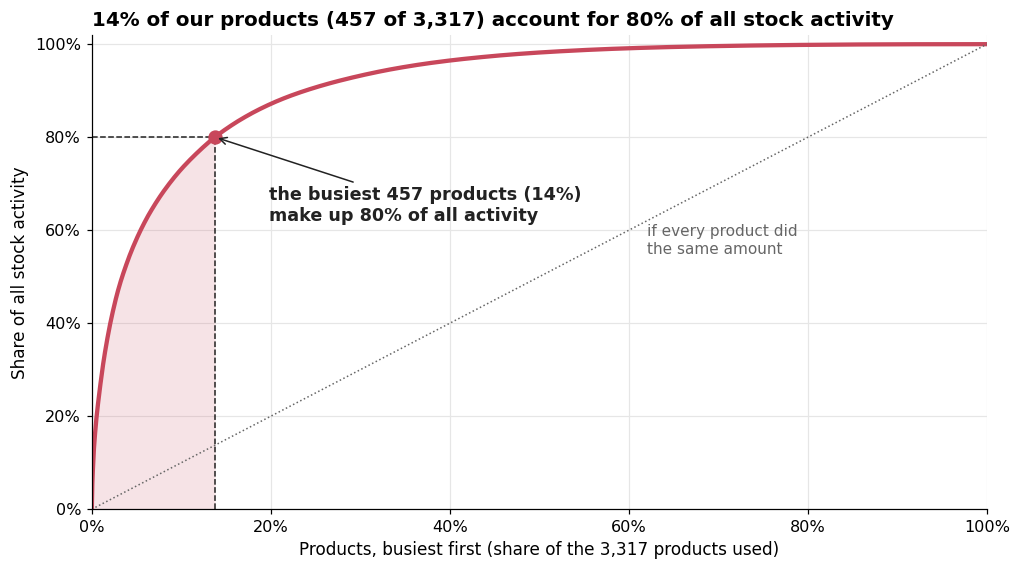

In [21]:
n80, n_moving = items_for_share(lines)
v = np.sort(lines[lines > 0].to_numpy(float))[::-1]
cum = np.insert(np.cumsum(v) / v.sum(), 0, 0)
share_x = np.linspace(0, 1, len(cum))
p80 = n80 / n_moving
fig, ax = plt.subplots(figsize=(10.5, 5.6))
ax.fill_between(share_x, 0, cum, where=share_x <= p80, color=BAD, alpha=.15, lw=0)
ax.plot(share_x, cum, color=BAD, lw=2.8)
ax.plot([0, 1], [0, 1], color=QUIET, lw=1, ls=":")
ax.text(0.62, 0.55, "if every product did\nthe same amount", color=QUIET, fontsize=10, rotation=0)
ax.plot([p80, p80], [0, 0.8], color=INK, lw=1, ls="--"); ax.plot([0, p80], [0.8, 0.8], color=INK, lw=1, ls="--")
ax.scatter([p80], [0.8], color=BAD, s=70, zorder=3)
ax.annotate(f"the busiest {n80:,} products ({p80:.0%})\nmake up 80% of all activity", (p80, 0.8), xytext=(p80 + 0.06, 0.62),
            fontsize=11.5, weight="bold", color=INK, arrowprops=dict(arrowstyle="->", color=INK))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_xlabel(f"Products, busiest first (share of the {n_moving:,} products used)"); ax.set_ylabel("Share of all stock activity")
ax.set_title(f"{p80:.0%} of our products ({n80:,} of {n_moving:,}) account for 80% of all stock activity", fontsize=13)
save(fig, "q3_1_few_products_do_most_work")

### Q3 chart 2: which product groups carry more than their share (scatter plot)
Each bubble is a product group: further right = more of our products, higher = more of our activity. Groups above the dotted line do more than their share of the work; bubble size = number of products.

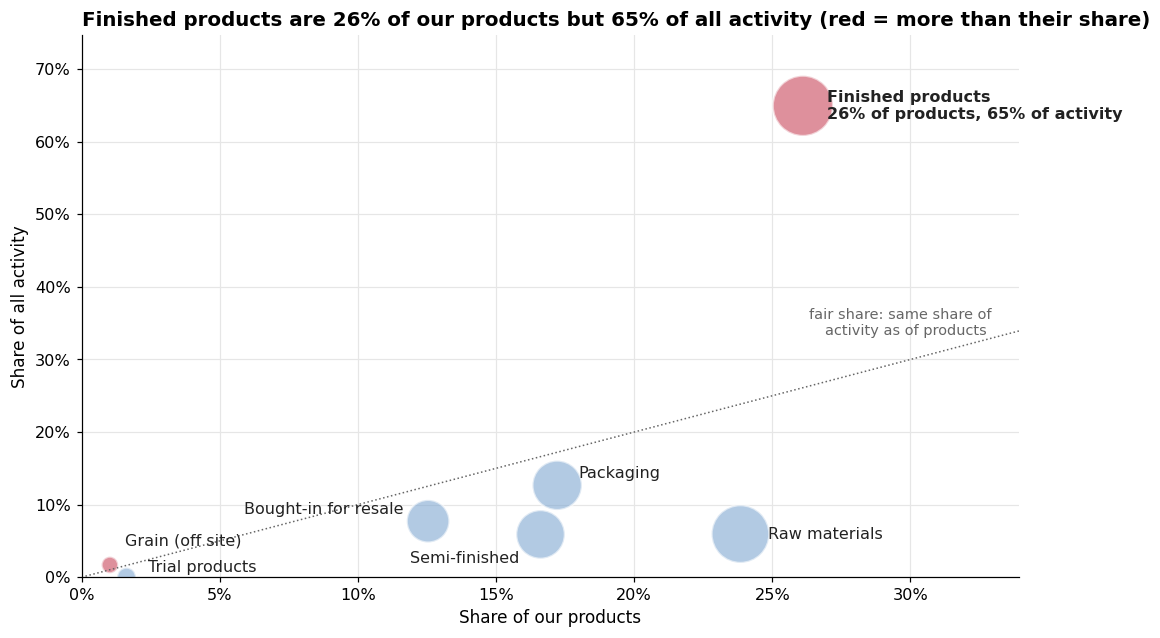

In [22]:
cat_lines = lines.to_frame("lines").join(pm.set_index("product_id").product_category)
cat = pd.DataFrame({"share_of_products": cat_lines.groupby("product_category").size() / len(cat_lines),
                    "share_of_activity": cat_lines.groupby("product_category").lines.sum() / cat_lines.lines.sum(),
                    "products": cat_lines.groupby("product_category").size()})
cat = cat[(cat.share_of_products >= 0.01) | (cat.share_of_activity >= 0.01)].sort_values("share_of_activity")
TABLES["q3_by_category"] = cat.reset_index()
PLAIN_CAT = {"FP": "Finished products", "RM": "Raw materials", "PackageRM": "Packaging", "SemiFinish": "Semi-finished",
             "TradedProd": "Bought-in for resale", "OnSiteGrn": "Grain (on site)", "OffSiteGrn": "Grain (off site)",
             "TrialProd": "Trial products", "ByProducts": "By-products"}
top = cat.share_of_activity.idxmax()
xlim_, ylim_ = cat.share_of_products.max() * 1.3, cat.share_of_activity.max() * 1.15
fig, ax = plt.subplots(figsize=(11, 6.4))
d = min(xlim_, ylim_)
ax.plot([0, d], [0, d], color=QUIET, lw=1, ls=":")
ax.text(d * .97, d * .97, "fair share: same share of\nactivity as of products ", color=QUIET, ha="right", va="bottom", fontsize=9.5)
colr = [BAD if a > p else CALM for p, a in zip(cat.share_of_products, cat.share_of_activity)]
ax.scatter(cat.share_of_products, cat.share_of_activity, s=cat.products / cat.products.max() * 1500 + 60,
           c=colr, alpha=.6, edgecolor="white", linewidth=1.5)
OFFSET = {"FP": (16, 0), "PackageRM": (14, 8), "SemiFinish": (-14, -16), "RM": (18, 0), "TradedProd": (-16, 8),
          "OffSiteGrn": (10, 16), "TrialProd": (14, 6), "OnSiteGrn": (10, 0), "ByProducts": (10, -6)}
for k, r in cat.iterrows():
    dx, dy = OFFSET.get(k, (10, 0))
    lab = f"{PLAIN_CAT.get(k, k)}" + (f"\n{r.share_of_products:.0%} of products, {r.share_of_activity:.0%} of activity" if k == top else "")
    ax.annotate(lab, (r.share_of_products, r.share_of_activity), xytext=(dx, dy), textcoords="offset points",
                ha="left" if dx > 0 else "right", va="center", fontsize=10.5, color=INK, weight="bold" if k == top else "normal")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlim(0, xlim_); ax.set_ylim(0, ylim_)
ax.set_xlabel("Share of our products"); ax.set_ylabel("Share of all activity")
ax.set_title(f"{PLAIN_CAT.get(top, top)} are {cat.at[top, 'share_of_products']:.0%} of our products "
             f"but {cat.at[top, 'share_of_activity']:.0%} of all activity (red = more than their share)", fontsize=13)
save(fig, "q3_2_product_groups")

### Q3 chart 3: sites that depend on a handful of products (bar chart)
For each site with at least 20 products in use: how many products make up 80% of that site's activity. Fewer products means more exposure if one of them is short.

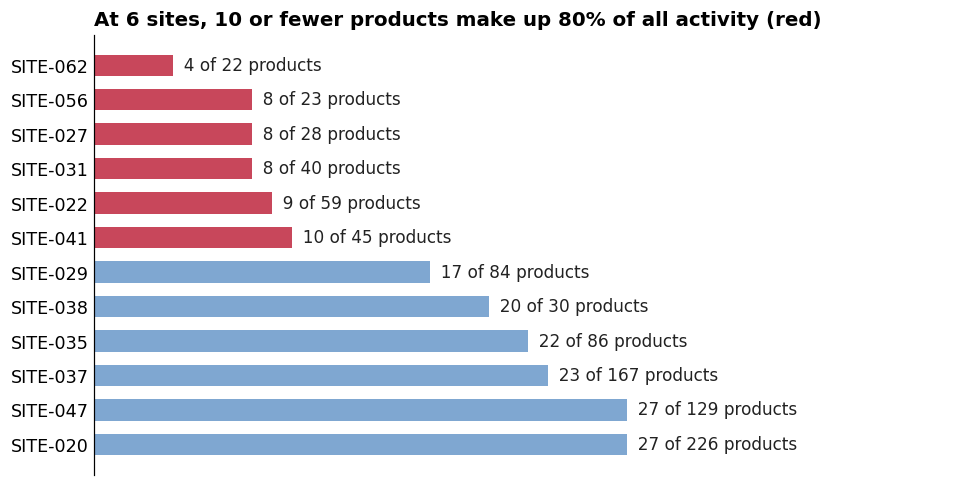

In [23]:
site_item = mo_stock.groupby(["site_id", "itemid"]).transaction_count.sum()
by_site = site_item.groupby(level=0).agg(gini=gini, n_items=lambda v: (v > 0).sum(),
                                          items_80=lambda v: items_for_share(v)[0], lines="sum")
TABLES["q3_by_site"] = by_site.reset_index()
dep = by_site[by_site.n_items >= 20].sort_values("items_80").head(12).iloc[::-1]
few = int((by_site[by_site.n_items >= 20].items_80 <= 10).sum())
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.barh(dep.index, dep.items_80, color=[BAD if v <= 10 else CALM for v in dep.items_80], height=.62)
for i, (v, n) in enumerate(zip(dep.items_80, dep.n_items)):
    ax.text(v, i, f"  {int(v)} of {int(n)} products", va="center", fontsize=11, color=INK)
plain_axes(ax); ax.set_xlim(0, dep.items_80.max() * 1.6)
ax.set_title(f"At {few} sites, 10 or fewer products make up 80% of all activity (red)", fontsize=13)
save(fig, "q3_3_sites_dependent_on_few_products")

### Q3 supporting tables (no chart)
Month-by-month stability of the top 20 products, and an ABC grouping (A = products in the top 80% of activity) used for stocking rules.

In [24]:
im = mo_stock.groupby(["movement_month", "itemid"]).transaction_count.sum()
rows_, prev = [], None
for m in MONTHS:
    v = im.loc[m] if m in im.index.get_level_values(0) else pd.Series(dtype=float)
    top20 = set(v.nlargest(20).index)
    rows_.append({"month": m, "top20_share": v.nlargest(20).sum() / v.sum() if v.sum() else np.nan,
                  "same_as_last_month": len(top20 & prev) / 20 if prev else np.nan})
    prev = top20
tm = pd.DataFrame(rows_)
TABLES["q3_top20_by_month"] = tm
abc = lines[lines > 0].sort_values(ascending=False)
cum = abc.cumsum() / abc.sum()
abc_cls = pd.Series(np.where(cum <= .80, "A", np.where(cum <= .95, "B", "C")), index=abc.index, name="ABC")
TABLES["q3_abc_groups"] = abc_cls.to_frame().join(q1[["product_name", "status"]]).reset_index(names="item_id")
tm

,month,top20_share,same_as_last_month
0,2025-07-01,0.21,NaN
1,2025-08-01,0.22,0.65
2,2025-09-01,0.23,0.65
3,2025-10-01,0.22,0.75
4,2025-11-01,0.22,0.70
5,2025-12-01,0.23,0.70
6,2026-01-01,0.22,0.65
7,2026-02-01,0.23,0.70
8,2026-03-01,0.22,0.70
9,2026-04-01,0.22,0.70


### Q3 chart 4: activity through the year (trend chart)
Total stock transactions per month, split into finished products and everything else.

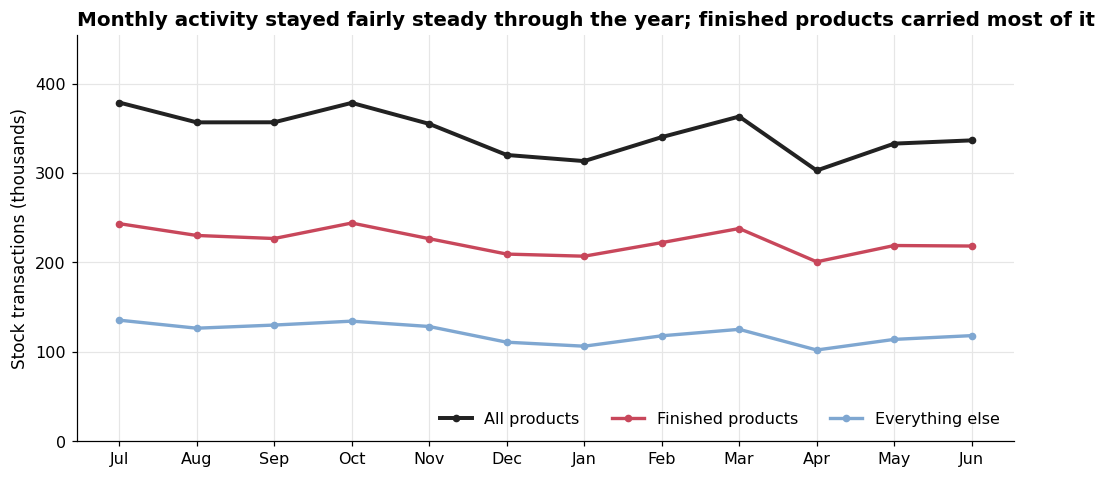

In [25]:
mt = (mo_stock.assign(group=np.where(mo_stock.product_category == "FP", "Finished products", "Everything else"))
      .groupby(["movement_month", "group"]).transaction_count.sum().unstack(fill_value=0).reindex(MONTHS, fill_value=0))
tot = mt.sum(axis=1)
swing = tot.max() / tot.min() if tot.min() else np.nan
fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(12)
ax.plot(x, tot / 1000, color=INK, lw=2.6, marker="o", ms=4, label="All products")
ax.plot(x, mt["Finished products"] / 1000, color=BAD, lw=2.2, marker="o", ms=4, label="Finished products")
ax.plot(x, mt["Everything else"] / 1000, color=CALM, lw=2.2, marker="o", ms=4, label="Everything else")
ax.set_xticks(x); ax.set_xticklabels([m[:3] for m in MONTH_LABELS])
ax.set_ylim(0, tot.max() / 1000 * 1.2); ax.set_ylabel("Stock transactions (thousands)")
ax.legend(loc="lower right", ncol=3)
trend_word = "stayed fairly steady" if swing < 1.35 else "rose and fell noticeably"
ax.set_title(f"Monthly activity {trend_word} through the year; finished products carried most of it", fontsize=13)
save(fig, "q3_4_activity_by_month")
TABLES["q3_activity_by_month"] = mt.assign(total=tot).reset_index()

### Q3 key messages

In [26]:
msgs = [
    f"{n80:,} products ({n80 / n_moving:.0%} of those used) account for 80% of all stock activity. "
    "Action: give these products the closest attention: automatic reordering, daily stock checks, a named owner.",
    f"{PLAIN_CAT.get(top, top)} are {cat.at[top, 'share_of_products']:.0%} of our products but "
    f"{cat.at[top, 'share_of_activity']:.0%} of the activity, so most day-to-day effort goes there.",
    f"At {few} sites, 10 or fewer products make up 80% of the site's activity. "
    "Action: make sure each of those products has a second supplier or a backup site.",
    f"Each month, about {tm.same_as_last_month.mean():.0%} of the top 20 products are the same as the month before, "
    "so the busiest products are fairly stable and can be planned with a steady routine.",
]
for m in msgs:
    print("•", m, "\n")

• 457 products (14% of those used) account for 80% of all stock activity. Action: give these products the closest attention: automatic reordering, daily stock checks, a named owner. 

• Finished products are 26% of our products but 65% of the activity, so most day-to-day effort goes there. 

• At 6 sites, 10 or fewer products make up 80% of the site's activity. Action: make sure each of those products has a second supplier or a backup site. 

• Each month, about 70% of the top 20 products are the same as the month before, so the busiest products are fairly stable and can be planned with a steady routine. 



---
# Q4. What else in the data looks wrong or worth fixing?
These checks look for records that are unused, missing or inconsistent. None of them changes the answers above much, but each one makes reporting harder or less reliable. The charts show how much of the system is clutter, and which fixes would help most.

In [27]:
checks = []
def check(area, name, df_or_n, detail=None):
    n = df_or_n if isinstance(df_or_n, (int, np.integer)) else len(df_or_n)
    checks.append({"area": area, "check": name, "affected": int(n)})
    if detail is not None:
        TABLES[f"q4_{len(checks):02d}"] = detail if isinstance(detail, pd.DataFrame) else pd.DataFrame(detail)

moving = set(mo.itemid)
# ---- products ----
nm = pm[pm.product_type.eq(0) & ~pm.product_id.isin(moving)]
check("Products", "Stocked items that never moved", nm, nm[["product_id", "product_name", "product_category", "lifecycle"]])
dup = pm[pm.duplicated("product_name", keep=False)].assign(moving=lambda d: d.product_id.isin(moving))
dup_both = dup.groupby("product_name").filter(lambda g: g.moving.sum() >= 2)
check("Products", "Repeated names where 2+ IDs move (possible duplicate SKUs)", dup_both.product_name.nunique(),
      dup_both[["product_name", "product_id", "product_category", "dataareaid", "moving"]].sort_values("product_name"))
svc = mo[mo.product_type.eq(2)].groupby(["itemid", "product_category"]).transaction_count.sum().reset_index()
check("Products", "Service items (type 2) with inventory transactions", svc.itemid.nunique(), svc)
obs = q1[q1.any_movement & q1.lifecycle.isin(["Obsolete", "End of life"])]
check("Products", "Obsolete / End of life items still moving", obs, obs.reset_index(names="item_id")[["item_id", "product_name", "lifecycle", "months_active", "last_transaction_date"]])
late = pm.merge(yr[["item_id", "first_transaction_date"]], left_on="product_id", right_on="item_id")
late = late[late.created_on > late.first_transaction_date + pd.Timedelta(days=1)]
check("Products", "Item created after its first transaction", late, late[["product_id", "created_on", "first_transaction_date"]])
blank_h = pm.category_level1.isna().sum()
check("Products", "Items with no sales hierarchy (category_level1 blank)", blank_h)
for c in ["netweight", "shelf_life", "best_before"]:
    check("Products", f"{c} not recorded (0 or blank)", int(pm.loc[pm.product_type.eq(0), c].isna().sum()))

# ---- units ----
case_rows = mo[mo.unitid_raw.astype(str) != mo.unitid.astype(str)]
check("Units", "Monthly rows with lower/mixed-case unit codes", case_rows, case_rows.groupby("unitid_raw").size().rename("rows").reset_index())
ns = yr[yr.unit_of_measure.eq("NS")]
check("Units", "Items transacting in NS (NON STOCK) unit", ns, ns[["item_id", "total_transaction_lines"]])
check("Units", "Orphan conversion rows (item not in master)", int((~conv_raw.item_id.isin(pm.product_id)).sum()))
pairs = set(zip(conv.item_id, conv.fromsymbol, conv.tosymbol)) | set(zip(conv.item_id, conv.tosymbol, conv.fromsymbol))
need = pm[pm.product_type.eq(0) & pm.pur_uom.notna() & pm.inv_uom.notna() & (pm.pur_uom != pm.inv_uom)]
noconv = need[[(r.product_id, r.pur_uom, r.inv_uom) not in pairs for r in need.itertuples()]]
check("Units", "Bought in a different unit with no conversion row", noconv, noconv[["product_id", "pur_uom", "inv_uom"]])
uom_mismatch = yr.merge(pm[["product_id", "inv_uom"]], left_on="item_id", right_on="product_id")
uom_mismatch = uom_mismatch[uom_mismatch.unit_of_measure != uom_mismatch.inv_uom]
check("Units", "Transaction unit differs from master inv_uom", uom_mismatch, uom_mismatch[["item_id", "unit_of_measure", "inv_uom"]])

# ---- sites and warehouses ----
idle_wh = loc[~loc.inventlocationid.isin(mo.warehouse_id)]
check("Warehouses", "Warehouses with no movement in the year", idle_wh, idle_wh.groupby(["inventsiteid"]).size().rename("idle_warehouses").reset_index())
check("Warehouses", "Third-party grain receival points (SITE-062)", int(loc.is_grain_point.sum()))
idle_site = site[~site.siteid.isin(mo.site_id)]
check("Sites", "Sites with no movement in the year", idle_site, idle_site)
no_wh = site[~site.siteid.isin(loc.inventsiteid)]
check("Sites", "Sites with no warehouse", no_wh, no_wh)
if "destinationcodeid_emp" in raw["inventsite"]:
    ds = raw["inventsite"][["siteid", "destinationcodeid_emp", "dataareaid"]].copy()
    ds["expected"] = np.where(ds.dataareaid.eq("nz01"), "NZP-" + ds.siteid, ds.siteid)
    bad = ds[ds.destinationcodeid_emp != ds.expected]
    check("Sites", "Destination code does not match site (e.g. SITE-038)", bad, bad)

# ---- transactions ----
d1 = mo[(mo.receipt_qty > 0) & mo.last_receipt_date.isna()]
d2 = mo[(mo.issue_qty > 0) & mo.last_issue_date.isna()]
check("Transactions", "Quantity without its last-date (receipt or issue)", len(d1) + len(d2))
ret = mo[(mo.reference.eq("Sales order") & (mo.receipt_qty > 0)) | (mo.reference.eq("Purchase order") & (mo.issue_qty > 0))]
check("Transactions", "Customer / supplier returns (receipt on SO, issue on PO)", ret.itemid.nunique(),
      ret.groupby(["reference", "site_id"]).agg(items=("itemid", "nunique"), lines=("transaction_count", "sum")).reset_index())
neg = yr[(yr.total_quantity_issued > 0) & (yr.total_quantity_received == 0)]
check("Transactions", "Issued all year with zero receipts (running down opening stock)", neg, neg[["item_id", "total_quantity_issued", "unit_of_measure"]])
recon_n = len(TABLES["recon_exceptions"])
check("Transactions", "Yearly vs monthly reconciliation exceptions", recon_n)

# transfer balance (KG only, so it can be summed)
tr = mo[mo.unitid.eq("KG") & mo.reference.isin(["Transfer order shipment", "Transfer order receive"])]
tb = tr.pivot_table(index="movement_month", columns="reference", values=["issue_qty", "receipt_qty"], aggfunc="sum").fillna(0)
if not tb.empty:
    ship = tb.get(("issue_qty", "Transfer order shipment"), 0); recv = tb.get(("receipt_qty", "Transfer order receive"), 0)
    TABLES["q4_transfer_balance_kg"] = pd.DataFrame({"shipped_kg": ship, "received_kg": recv, "gap_kg": ship - recv}).reset_index()
sc = mo[mo.reference.eq("Inventory status change")].groupby("site_id").transaction_count.sum().sort_values(ascending=False)
TABLES["q4_status_change_by_site"] = sc.rename("status_change_lines").reset_index()
scrap = mo[mo.reference.eq("Transfer order scrap")].groupby(["site_id", "unitid"]).issue_qty.sum()
TABLES["q4_scrap_by_site"] = scrap.rename("scrapped_qty").reset_index()

# ---- cost indexes: ties that are really "none" ----
check("Cost", "Items tied at cost_adjustment_index 46.2 (no adjustment)", int(np.isclose(yr.cost_adjustment_index, 46.2).sum()))
check("Cost", "Items tied at cost_volatility_index 1.7 (no variation)", int(np.isclose(yr.cost_volatility_index, 1.7).sum()))

scorecard = pd.DataFrame(checks)
TABLES["q4_scorecard"] = scorecard
scorecard

,area,check,affected
0,Products,Stocked items that never moved,2099
1,Products,Repeated names where 2+ IDs move (possible dup...,128
2,Products,Service items (type 2) with inventory transact...,16
3,Products,Obsolete / End of life items still moving,551
4,Products,Item created after its first transaction,0
5,Products,Items with no sales hierarchy (category_level1...,3963
6,Products,netweight not recorded (0 or blank),224
7,Products,shelf_life not recorded (0 or blank),178
8,Products,best_before not recorded (0 or blank),197
9,Units,Monthly rows with lower/mixed-case unit codes,9


### Q4 chart 1: what is in the system vs what was actually used (pie charts)
Each pie is everything in the system; the blue slice is what was actually used this year.

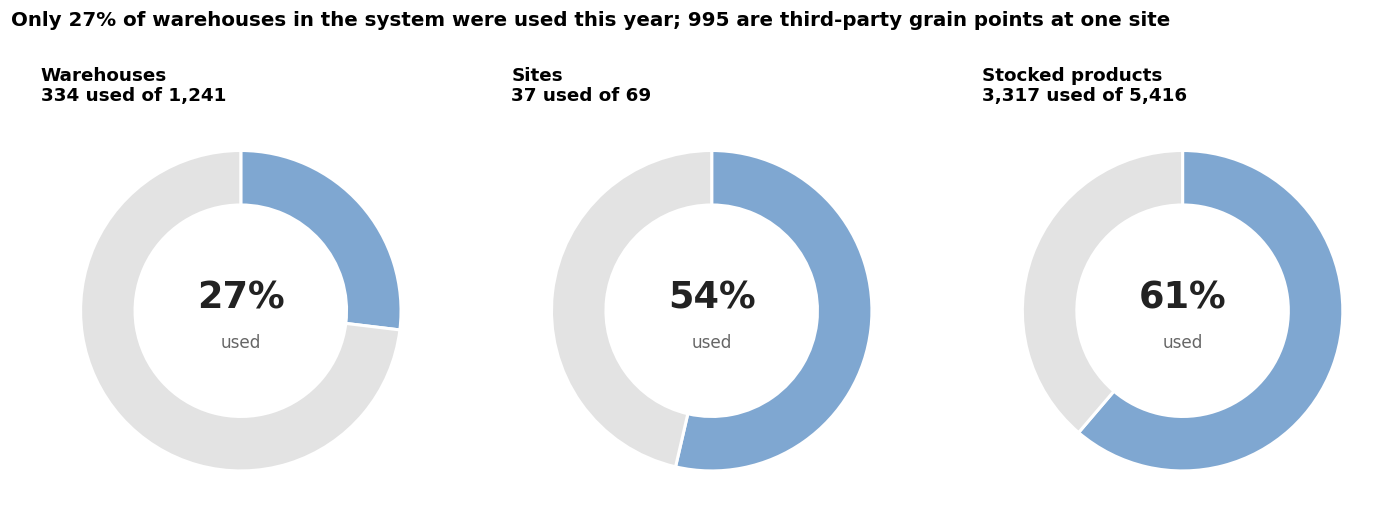

In [28]:
clutter = pd.DataFrame([
    ("Warehouses", len(loc), mo.warehouse_id.nunique()),
    ("Sites", len(site), mo.site_id.nunique()),
    ("Stocked products", len(q1), int(q1.any_movement.sum())),
], columns=["what", "in_system", "used"]).set_index("what")
fig, axes = plt.subplots(1, 3, figsize=(13, 4.8))
for ax, (w, r) in zip(axes, clutter.iterrows()):
    share = r.used / r.in_system
    ax.pie([r.used, r.in_system - r.used], colors=[CALM, "#E3E3E3"], startangle=90, counterclock=False,
           wedgeprops=dict(width=0.34, edgecolor="white", linewidth=2))
    ax.text(0, 0.08, f"{share:.0%}", ha="center", va="center", fontsize=24, weight="bold", color=INK)
    ax.text(0, -0.2, "used", ha="center", va="center", fontsize=11, color=QUIET)
    ax.set_title(f"{w}\n{r.used:,} used of {r.in_system:,}", fontsize=12)
    ax.set_aspect("equal")
w = clutter.loc["Warehouses"]
fig.suptitle(f"Only {w.used / w.in_system:.0%} of warehouses in the system were used this year; "
             f"{loc.is_grain_point.sum():,} are third-party grain points at one site", x=0.01, ha="left", weight="bold", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.9])
save(fig, "q4_1_system_vs_used")
TABLES["q4_system_vs_used"] = clutter.reset_index()

### Q4 chart 2: the data fixes that would help most (bar chart)
Each bar is one problem, written as what it means for the business, with how many products or records it affects.

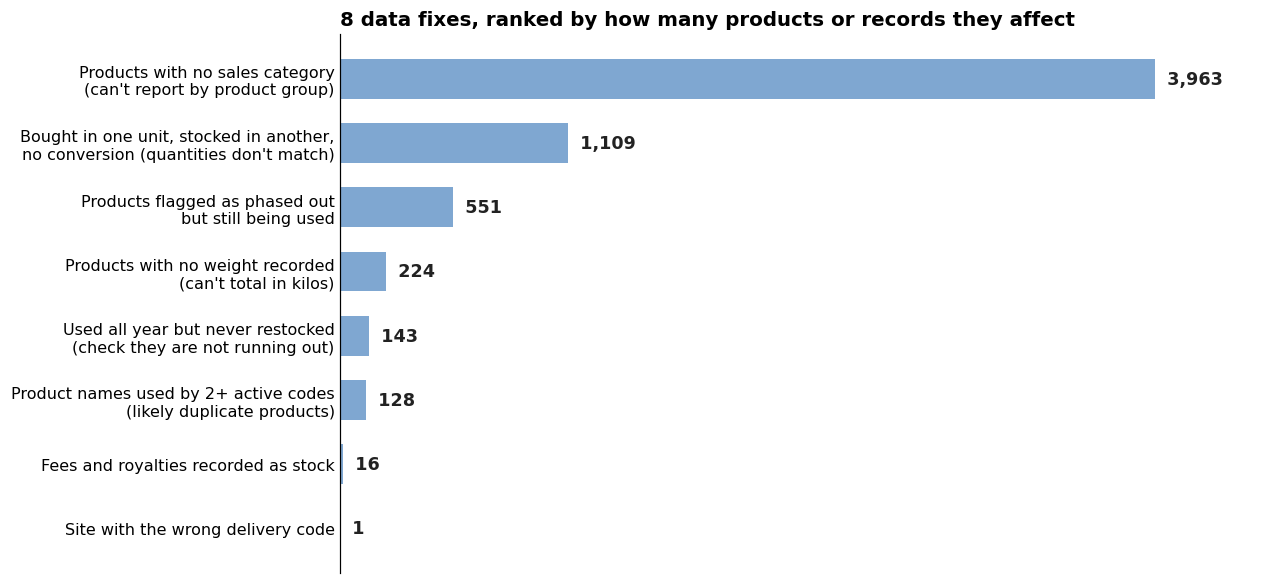

In [29]:
PLAIN_ISSUE = {
    "Items with no sales hierarchy (category_level1 blank)": "Products with no sales category\n(can't report by product group)",
    "Bought in a different unit with no conversion row": "Bought in one unit, stocked in another,\nno conversion (quantities don't match)",
    "Obsolete / End of life items still moving": "Products flagged as phased out\nbut still being used",
    "netweight not recorded (0 or blank)": "Products with no weight recorded\n(can't total in kilos)",
    "Issued all year with zero receipts (running down opening stock)": "Used all year but never restocked\n(check they are not running out)",
    "Repeated names where 2+ IDs move (possible duplicate SKUs)": "Product names used by 2+ active codes\n(likely duplicate products)",
    "Service items (type 2) with inventory transactions": "Fees and royalties recorded as stock",
    "Destination code does not match site (e.g. SITE-038)": "Site with the wrong delivery code",
}
fix = scorecard[scorecard.check.isin(PLAIN_ISSUE)].copy()
fix["label"] = fix.check.map(PLAIN_ISSUE)
fix = fix.sort_values("affected")
fig, ax = plt.subplots(figsize=(11, 0.62 * len(fix) + 1.4))
ax.barh(fix.label, fix.affected, color=CALM, height=.62)
for i, v in enumerate(fix.affected):
    ax.text(v, i, f"  {v:,}", va="center", fontsize=11.5, weight="bold", color=INK)
plain_axes(ax); ax.tick_params(axis="y", labelsize=10.5); ax.set_xlim(0, fix.affected.max() * 1.15)
ax.set_title(f"{len(fix)} data fixes, ranked by how many products or records they affect", fontsize=13)
save(fig, "q4_2_data_fixes")
TABLES["q4_data_fixes_plain"] = fix[["label", "affected", "area", "check"]].iloc[::-1]

### Q4 key messages

In [30]:
sv = clutter
def n(check):
    v = scorecard.loc[scorecard.check == check, "affected"]
    return int(v.iloc[0]) if len(v) else 0
msgs = [
    f"Only {sv.at['Warehouses', 'used']:,} of {sv.at['Warehouses', 'in_system']:,} warehouses, "
    f"{sv.at['Sites', 'used']} of {sv.at['Sites', 'in_system']} sites and {sv.at['Stocked products', 'used']:,} of "
    f"{sv.at['Stocked products', 'in_system']:,} stocked products were used this year. "
    "Action: archive unused records so planning runs and reports only show what is real.",
    f"{n('Bought in a different unit with no conversion row'):,} products are bought in one unit and stocked in another "
    "with no conversion set up, so purchase and stock quantities cannot be compared. Action: add the conversions.",
    f"{n('Items with no sales hierarchy (category_level1 blank)'):,} products have no sales category, so most reporting "
    "by product group is incomplete. Action: complete the categories for the products that move.",
    f"{n('Obsolete / End of life items still moving'):,} products flagged as phased out are still being used, and "
    f"{n('Repeated names where 2+ IDs move (possible duplicate SKUs)'):,} product names are shared by two or more active codes. "
    "Action: correct the status, and merge true duplicates.",
    f"{n('Service items (type 2) with inventory transactions')} fees or royalties are recorded as stock, and one site "
    "(SITE-038) carries another site's delivery code. Action: small fixes for the system owner.",
]
for m in msgs:
    print("•", m, "\n")

• Only 334 of 1,241 warehouses, 37 of 69 sites and 3,317 of 5,416 stocked products were used this year. Action: archive unused records so planning runs and reports only show what is real. 

• 1,109 products are bought in one unit and stocked in another with no conversion set up, so purchase and stock quantities cannot be compared. Action: add the conversions. 

• 3,963 products have no sales category, so most reporting by product group is incomplete. Action: complete the categories for the products that move. 

• 551 products flagged as phased out are still being used, and 128 product names are shared by two or more active codes. Action: correct the status, and merge true duplicates. 

• 16 fees or royalties are recorded as stock, and one site (SITE-038) carries another site's delivery code. Action: small fixes for the system owner. 



---
## Export all result tables
One Excel workbook with a sheet per table, plus the figures already saved in `outputs/figures/`.

In [31]:
out = OUT_DIR / "analysis_tables.xlsx"
with pd.ExcelWriter(out) as xw:
    for name, df in TABLES.items():
        df.to_excel(xw, sheet_name=name[:31], index=False)
print(f"Saved {len(TABLES)} tables to {out.resolve()}")
print(f"Figures in {FIG_DIR.resolve()}:")
for p in sorted(FIG_DIR.glob("*.png")):
    print("  ", p.name)

Saved 37 tables to C:\Users\genai\OneDrive\projects\mcu_biz-analytics-techniques\a3\outputs\analysis_tables.xlsx
Figures in C:\Users\genai\OneDrive\projects\mcu_biz-analytics-techniques\a3\outputs\figures:
   00_reference_mix.png
   q1_1_where_products_stand.png
   q1_2_falling_products.png
   q1_volatility_1_what_it_looks_like.png
   q1_volatility_2_how_many_and_why.png
   q1_volatility_3_two_risks.png
   q2_1_what_caused_unusual_months.png
   q2_2_unusual_month_example.png
   q2_3_where_unusual_months_happen.png
   q2_4_unusual_months_by_month.png
   q3_1_few_products_do_most_work.png
   q3_2_product_groups.png
   q3_3_sites_dependent_on_few_products.png
   q3_4_activity_by_month.png
   q4_1_system_vs_used.png
   q4_2_data_fixes.png
